<a href="https://colab.research.google.com/github/Claudio-Ferriz/Proyecto-OP/blob/main/Proyecto_OP.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Análisis de encuestas y resultados electorales por la Ciudad Autónoma de Buenos Aires (CABA) y la República Argentina
Este notebook realiza un análisis integral que incluye:
1. **Carga y limpieza de datos**
2. **Análisis exploratorio (EDA)**
3. **Resultados electorales de CABA 2025** (Legislatura porteña y diputados nacionales)
4. **Clima de opinión nacional y electorado joven** (OPSA UBA, ESPOP UdeSA y Eunomia)
5. **Principales preocupaciones de la ciudadanía de CABA** (encuestas reales de 2026)

> **Importante:** las encuestas de CABA de junio a agosto de 2026 que se grafican en las secciones 3 a 6 son **datos ficticios** de una consultora ficticia, **FK Consultores**, construidos con base en las encuestas de DC Consultores (ver sección 2.1). Las secciones 7, 8 y 9 usan datos reales.


---
## 0. Configuración e Importación de Librerías

In [31]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# Estilo global de visualizaciones
plt.rcParams.update({
    'figure.dpi': 120,
    'font.family': 'DejaVu Sans',
    'axes.spines.top': False,
    'axes.spines.right': False,
})
sns.set_style('whitegrid')
PALETTE = 'tab10'

print('✅ Librerías cargadas correctamente')

✅ Librerías cargadas correctamente


---
## 1. Carga y Limpieza de Datos

In [32]:
# --- Encuestas en CABA ---
df_encuestas = pd.read_excel(
    'https://github.com/Claudio-Ferriz/Proyecto-OP/raw/refs/heads/main/Encuentas%20en%20CABA.xlsx'
)

# Eliminar columnas 'Unnamed'
df_encuestas = df_encuestas.drop(columns=[c for c in df_encuestas.columns if c.startswith('Unnamed')])

print(f'📊 Encuestas en CABA: {df_encuestas.shape[0]:,} registros | {df_encuestas.shape[1]} columnas')
df_encuestas.head(3)

📊 Encuestas en CABA: 2 registros | 14 columnas


,Localidad,Tipo de Encuesta,Tamaño de la muestra,Margen de error (%),Consultora,Link,Mes,Fecha,Voto en 2027 como Continuidad,Voto en 2027 como Cambio de Rumbo,Indice Desarrollo Humano,PBI per capita (PPA),Tasa Desempleo,Inflación
0,CABA,NaN,1130,NaN,DC Consultores,https://www.perfil.com/noticias/politica/encue...,Junio,2026-06-16,"52,7","47,3",NaN,NaN,NaN,NaN
1,CABA,NaN,1360,NaN,DC Consultores,https://www.perfil.com/noticias/politica/encue...,Julio,2026-07-22,"51,7","48,3",NaN,NaN,NaN,NaN


In [33]:
# --- Encuesta de intención de voto por CABA ---
df_encuesta_intención_voto = pd.read_excel(
    'https://github.com/Claudio-Ferriz/Proyecto-OP/raw/refs/heads/main/Encuestas%20de%20intenci%C3%B3n%20de%20voto%20por%20CABA%20.xlsx'
)

print(f'📊 Encuesta de intención de voto por CABA: {df_encuesta_intención_voto.shape[0]:,} registros | {df_encuesta_intención_voto.shape[1]} columnas')
df_encuesta_intención_voto.head(3)

📊 Encuesta de intención de voto por CABA: 2 registros | 20 columnas


,Localidad,Tipo de Encuesta,Tamaño de la muestra,Margen de error (%),Consultora,Link,Mes,Fecha,Leandro Santoro,Jorge Macri,Patricia Bullrich,Victoria Villarruel,Peronismo,PRO,La Libertad Avanza,Opción de centro derecha,Indice Desarrollo Humano,PBI per capita (PPA),Tasa Desempleo,Inflación
0,CABA,NaN,1360,NaN,DC Consultores,https://www.perfil.com/noticias/politica/encue...,Julio,2026-07-22,NaN,NaN,NaN,NaN,"19,8","26,7","30,1","23,4",NaN,NaN,NaN,NaN
1,CABA,NaN,918,"2,5",DC Consultores,https://www.perfil.com/noticias/amp/politica/e...,Agosto,2026-08-27,"19,7","31,2","32,8","16,4","13,8","38,4","14,2","33,6",NaN,NaN,NaN,NaN


---
## 2. Preparación de datos para las visualizaciones

Los Excel traen los porcentajes como **texto con coma decimal** (por ejemplo `"52,7"`), así que primero los convertimos a número. También definimos la paleta de colores y unas funciones de formato en español que reutilizan todos los gráficos.

In [34]:
# ============================================================
# 2. PREPARACIÓN DE DATOS Y ESTILO
# ============================================================
import textwrap
from matplotlib.patches import Patch
from matplotlib.lines import Line2D

# --- Conversión de "52,7" (texto) -> 52.7 (número) ---
def a_numero(serie):
    return pd.to_numeric(serie.astype(str).str.replace(',', '.', regex=False), errors='coerce')

COL_CONT   = 'Voto en 2027 como Continuidad'
COL_CAMBIO = 'Voto en 2027 como Cambio de Rumbo'
PARTIDOS   = ['Peronismo', 'PRO', 'La Libertad Avanza', 'Opción de centro derecha']
CANDIDATOS_BASE = ['Leandro Santoro', 'Jorge Macri', 'Patricia Bullrich', 'Victoria Villarruel']   # los de la encuesta original (DC)

enc = df_encuestas.copy()
vot = df_encuesta_intención_voto.copy()

for c in [COL_CONT, COL_CAMBIO]:
    enc[c] = a_numero(enc[c])
for c in PARTIDOS + CANDIDATOS_BASE + ['Margen de error (%)']:
    vot[c] = a_numero(vot[c])
enc['Fecha'] = pd.to_datetime(enc['Fecha'])
vot['Fecha'] = pd.to_datetime(vot['Fecha'])

# ------------------------------------------------------------
# AJUSTE FICTICIO: FK Consultores (con base en DC Consultores)
# ------------------------------------------------------------
CONSULTORA_FICTICIA = 'FK Consultores'
FUENTE = 'FK Consultores (datos ficticios; base: DC Consultores)'
BRIONES, BRIONES_AGO = 'Beltrán Briones', 7.2           # intención de voto ficticia en agosto (%)
CANDIDATOS = CANDIDATOS_BASE + [BRIONES]

vot_dc = vot[['Mes', 'Fecha'] + CANDIDATOS_BASE].copy()   # valores originales (DC), solo para trazabilidad
for d in (enc, vot):
    d['Consultora'] = CONSULTORA_FICTICIA

vot[BRIONES] = np.nan
con_cand = vot[CANDIDATOS_BASE].notna().all(axis=1)       # solo el relevamiento que trae candidatos (agosto)
factor = (100 - BRIONES_AGO) / vot.loc[con_cand, CANDIDATOS_BASE].sum(axis=1)   # resta proporcional a cada candidato
vot.loc[con_cand, CANDIDATOS_BASE] = vot.loc[con_cand, CANDIDATOS_BASE].mul(factor, axis=0).round(1)
vot.loc[con_cand, BRIONES] = BRIONES_AGO
assert (vot.loc[con_cand, CANDIDATOS].sum(axis=1).sub(100).abs() < 0.051).all(), 'La suma de candidatos debe dar 100%'

# --- Paleta y estilo ---
FONDO, TEXTO, GRIS, PISTA = '#FFFFFF', '#1F2937', '#6B7280', '#EEF0F3'
COLOR_CONT, COLOR_CAMBIO = '#1D4E89', '#E4572E'
COLOR_PARTIDO = {'Peronismo': '#4BA3E3', 'PRO': '#F5B700',
                 'La Libertad Avanza': '#6C3FB5', 'Opción de centro derecha': '#2A9D8F'}
COLOR_CANDIDATO = {'Leandro Santoro': '#4BA3E3', 'Jorge Macri': '#F5B700',
                   'Patricia Bullrich': '#6C3FB5', 'Victoria Villarruel': '#D1593F',
                   'Beltrán Briones': '#3BB273'}

# --- Formatos en español ---
def fmt(v, dec=1):
    return f'{v:.{dec}f}'.replace('.', ',')

def fmt_s(v, dec=1):                      # con signo: +1,0 / −6,0
    return f'{v:+.{dec}f}'.replace('.', ',').replace('-', '−')

def fmt_n(n):
    return f'{int(n):,}'.replace(',', '.')

def titulo_panel(fila):
    return f"{fila['Mes']} {fila['Fecha']:%Y}"

def descripcion(fila):
    return f"{fila['Consultora']} (datos ficticios) · n = {fmt_n(fila['Tamaño de la muestra'])} · {fila['Fecha']:%d/%m/%Y}"

def pie_figura(fig, texto):
    fig.text(0.5, 0.012, texto, ha='center', fontsize=9.5, color=GRIS)

# --- Ficha técnica de los relevamientos disponibles ---
ficha = (pd.concat([enc, vot])
           .drop_duplicates(subset='Fecha')
           [['Fecha', 'Mes', 'Consultora', 'Tamaño de la muestra', 'Margen de error (%)']]
           .sort_values('Fecha').reset_index(drop=True))
ficha['Fecha'] = ficha['Fecha'].dt.strftime('%d/%m/%Y')
ficha['Margen de error (%)'] = ficha['Margen de error (%)'].map(lambda v: '—' if pd.isna(v) else f'±{fmt(v)}')
print('✅ Datos convertidos y estilo definido')
ficha

✅ Datos convertidos y estilo definido


,Fecha,Mes,Consultora,Tamaño de la muestra,Margen de error (%)
0,16/06/2026,Junio,FK Consultores,1130,—
1,22/07/2026,Julio,FK Consultores,1360,—
2,27/08/2026,Agosto,FK Consultores,918,"±2,5"


### 2.1 Aclaración: datos ficticios (FK Consultores)
Las encuestas de CABA de junio a agosto de 2026 que usan las secciones 3 a 6 son **datos ficticios** de una consultora ficticia, **FK Consultores**, construidos con base en las encuestas de DC Consultores. Los cambios respecto de la base real son:

- Se renombró la consultora: **DC Consultores → FK Consultores**.
- Se incorporó a **Beltrán Briones** en la intención de voto por candidato de agosto, con **7,2%**.
- Para llegar a ese valor se restaron puntos de forma **proporcional** a los otros cuatro candidatos (cada uno multiplicado por 0,927, redondeado a un decimal), de modo que los cinco suman 100%. Como los cuatro valores originales sumaban 100,1% por redondeo, la resta total es de 7,3 pp.
- Los datos de continuidad/cambio de rumbo y de intención de voto por espacio político **no se modificaron**.

En las secciones 7, 8 y 9 los datos son reales y no están afectados por este ajuste.

In [35]:
# ============================================================
# 2.1 · Ajuste ficticio: de DC Consultores (base) a FK Consultores
# ============================================================
agosto = vot[con_cand].iloc[0]
base   = vot_dc[con_cand].iloc[0]
tabla_ajuste = pd.DataFrame({
    'Candidato': CANDIDATOS,
    'DC Consultores (base real, %)': [a_numero(pd.Series([base[c]])).iloc[0] if c in CANDIDATOS_BASE else np.nan for c in CANDIDATOS],
    'FK Consultores (ficticio, %)': [float(agosto[c]) for c in CANDIDATOS],
})
tabla_ajuste['Variación (pp)'] = tabla_ajuste['FK Consultores (ficticio, %)'] - tabla_ajuste['DC Consultores (base real, %)']
print(f"Suma FK: {fmt(tabla_ajuste['FK Consultores (ficticio, %)'].sum())}% · "
      f"Briones: +{fmt(BRIONES_AGO)} pp · Resta total a los otros cuatro: {fmt(-tabla_ajuste['Variación (pp)'].iloc[:-1].sum())} pp")
tabla_ajuste.round(1)

Suma FK: 100,0% · Briones: +7,2 pp · Resta total a los otros cuatro: 7,3 pp


,Candidato,"DC Consultores (base real, %)","FK Consultores (ficticio, %)",Variación (pp)
0,Leandro Santoro,19.7,18.3,-1.4
1,Jorge Macri,31.2,28.9,-2.3
2,Patricia Bullrich,32.8,30.4,-2.4
3,Victoria Villarruel,16.4,15.2,-1.2
4,Beltrán Briones,NaN,7.2,NaN


---
## 3. Voto en 2027: Continuidad vs. Cambio de Rumbo
Un gráfico circular por relevamiento (`df_encuestas`). En el centro de cada uno se muestra la ventaja en **puntos porcentuales (pp)**.

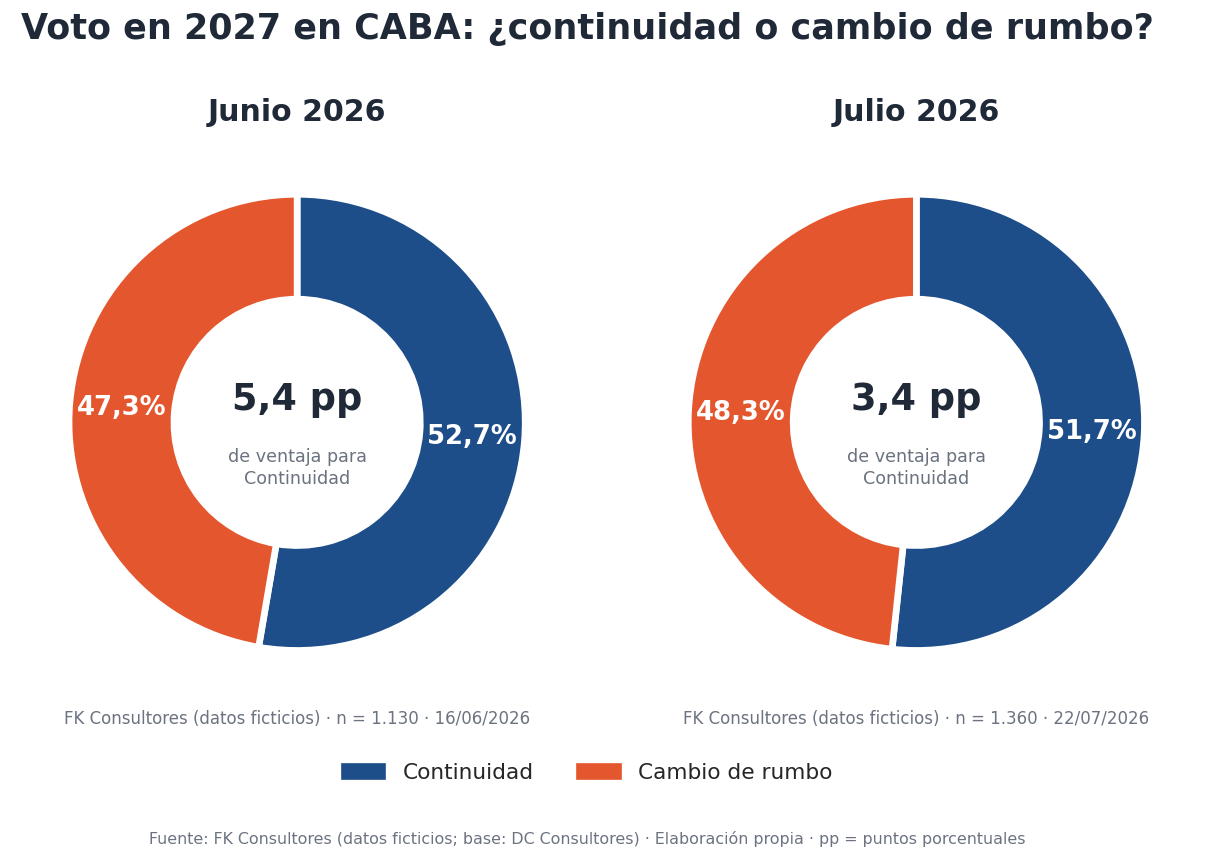

In [36]:
# ============================================================
# GRÁFICO 1 · Continuidad vs. Cambio de Rumbo (un círculo por registro)
# ============================================================
def donut(ax, fila):
    valores = [fila[COL_CONT], fila[COL_CAMBIO]]
    colores = [COLOR_CONT, COLOR_CAMBIO]
    wedges, _ = ax.pie(valores, colors=colores, startangle=90, counterclock=False,
                       wedgeprops=dict(width=0.46, edgecolor=FONDO, linewidth=4))
    for w, v in zip(wedges, valores):
        ang = np.deg2rad((w.theta1 + w.theta2) / 2)
        ax.text(0.77 * np.cos(ang), 0.77 * np.sin(ang), f'{fmt(v)}%',
                ha='center', va='center', fontsize=15.5, fontweight='bold', color='white')
    ventaja = valores[0] - valores[1]
    lider = 'Continuidad' if ventaja > 0 else 'Cambio de rumbo'
    ax.text(0, 0.10, f'{fmt(abs(ventaja))} pp', ha='center', va='center',
            fontsize=22, fontweight='bold', color=TEXTO)
    ax.text(0, -0.20, f'de ventaja para\n{lider}', ha='center', va='center',
            fontsize=10.5, color=GRIS, linespacing=1.3)
    ax.set_title(titulo_panel(fila), fontsize=18, fontweight='bold', color=TEXTO, pad=10)
    ax.text(0, -1.30, descripcion(fila), ha='center', va='center', fontsize=10, color=GRIS)

fig, axes = plt.subplots(1, 2, figsize=(13, 7.2), facecolor=FONDO)
for ax, (_, fila) in zip(axes, enc.iterrows()):
    donut(ax, fila)

fig.suptitle('Voto en 2027 en CABA: ¿continuidad o cambio de rumbo?',
             fontsize=21, fontweight='bold', color=TEXTO, y=0.975)
fig.legend(handles=[Patch(color=COLOR_CONT, label='Continuidad'),
                    Patch(color=COLOR_CAMBIO, label='Cambio de rumbo')],
           loc='lower center', ncol=2, frameon=False, fontsize=13, bbox_to_anchor=(0.5, 0.06))
pie_figura(fig, f'Fuente: {FUENTE} · Elaboración propia · pp = puntos porcentuales')
fig.subplots_adjust(top=0.83, bottom=0.17, wspace=0.05)
plt.show()

---
## 4. Intención de voto por espacio político
Un gráfico de barras horizontales por cada relevamiento de `df_encuesta_intención_voto` (Peronismo, PRO, La Libertad Avanza y Opción de centro derecha). Ambos usan la **misma escala** para poder compararlos a simple vista.

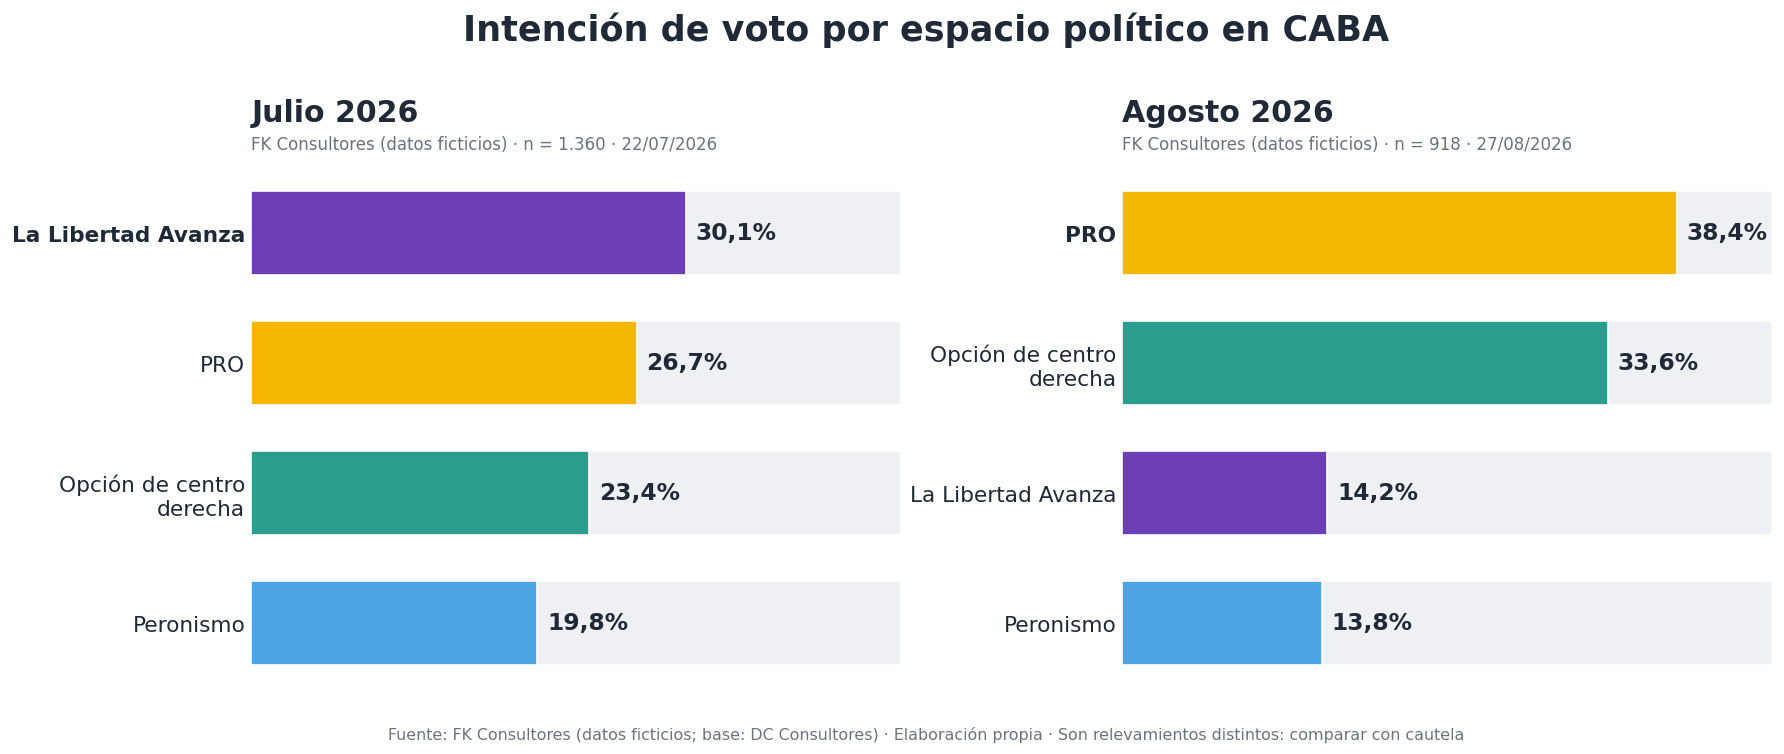

In [37]:
# ============================================================
# Función reutilizable para barras horizontales
# ============================================================
def barras_h(ax, serie, colores, xmax, titulo, subtitulo):
    s = serie.sort_values(ascending=True)            # el mayor queda arriba
    claves = list(s.index)
    etiquetas = [textwrap.fill(k, 18) for k in claves]
    pos = np.arange(len(s))
    ax.barh(pos, [xmax] * len(s), color=PISTA, height=0.64, zorder=0)          # pista gris de fondo
    barras = ax.barh(pos, s.values, color=[colores[k] for k in claves], height=0.64, zorder=2)
    for b, v in zip(barras, s.values):
        ax.text(v + xmax * 0.015, b.get_y() + b.get_height() / 2, f'{fmt(v)}%',
                va='center', ha='left', fontsize=14, fontweight='bold', color=TEXTO, zorder=3)
    ax.set_yticks(pos)
    ax.set_yticklabels(etiquetas)
    ax.get_yticklabels()[-1].set_fontweight('bold')                             # resalta al líder
    ax.set_xlim(0, xmax)
    ax.set_xticks([])
    ax.tick_params(axis='y', length=0, labelsize=13, labelcolor=TEXTO)
    for sp in ax.spines.values():
        sp.set_visible(False)
    ax.grid(False)
    ax.set_title(titulo, loc='left', fontsize=18, fontweight='bold', color=TEXTO, pad=28)
    ax.text(0, 1.035, subtitulo, transform=ax.transAxes, fontsize=10, color=GRIS)

# ============================================================
# GRÁFICO 2 · Espacios políticos, un gráfico por registro
# ============================================================
xmax_part = np.ceil(vot[PARTIDOS].max().max() / 5) * 5 + 5      # escala común

fig, axes = plt.subplots(1, 2, figsize=(15, 6.2), facecolor=FONDO)
for ax, (_, fila) in zip(axes, vot.iterrows()):
    barras_h(ax, fila[PARTIDOS].astype(float), COLOR_PARTIDO, xmax_part,
             titulo_panel(fila), descripcion(fila))

fig.suptitle('Intención de voto por espacio político en CABA',
             fontsize=21, fontweight='bold', color=TEXTO, y=0.99)
pie_figura(fig, f'Fuente: {FUENTE} · Elaboración propia · Son relevamientos distintos: comparar con cautela')
fig.subplots_adjust(top=0.78, bottom=0.08, wspace=0.34, left=0.125, right=0.97)
plt.show()

---
## 5. Intención de voto por candidato (segundo registro)
Solo el segundo relevamiento (agosto) trae datos por candidato. En esta versión se **incorpora a Beltrán Briones con 7,2%** (dato ficticio, ver sección 2.1) y los otros cuatro candidatos ceden puntos de forma proporcional. Si la diferencia entre los dos primeros es menor al margen de error informado, el gráfico lo aclara.

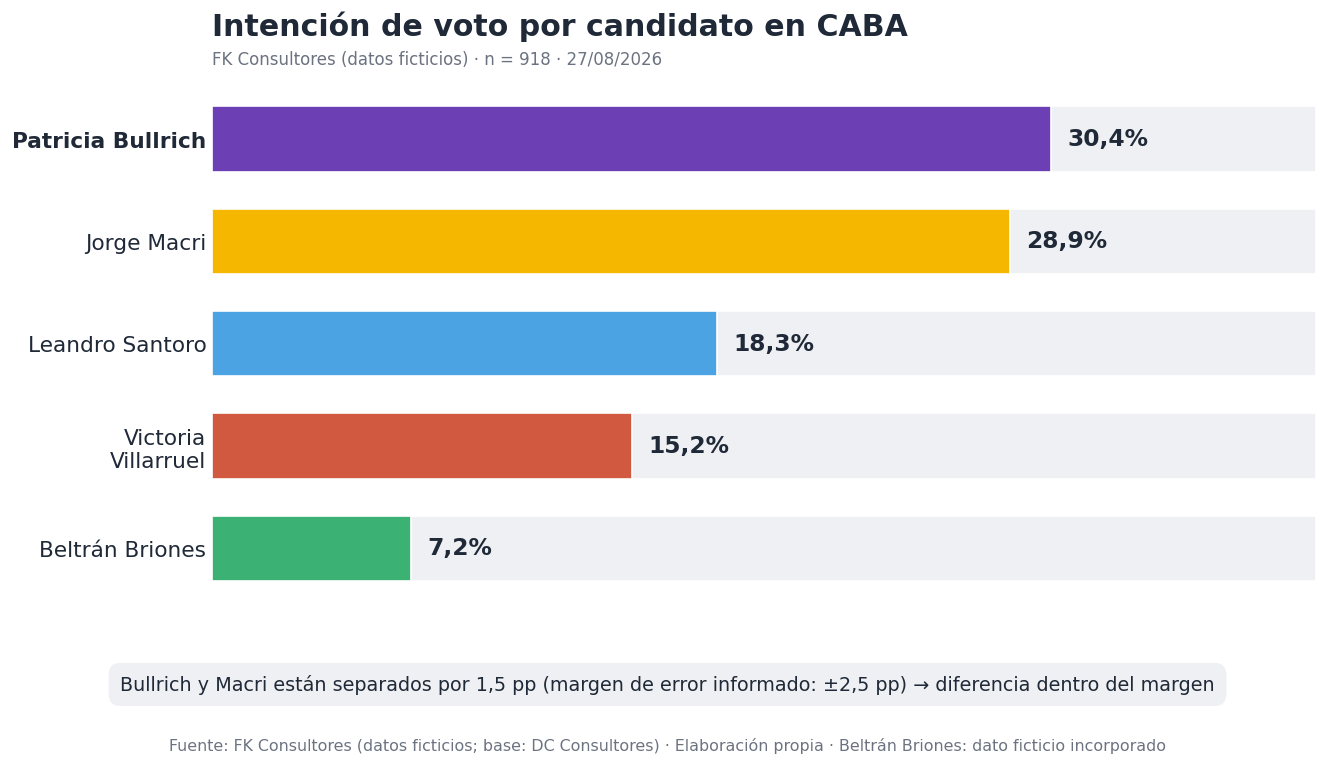

In [38]:
# ============================================================
# GRÁFICO 3 · Candidatos (segundo registro)
# ============================================================
fila = vot.iloc[1]
cand = fila[CANDIDATOS].astype(float)
xmax_cand = np.ceil(cand.max() / 5) * 5 + 5

fig, ax = plt.subplots(figsize=(11.5, 6.8), facecolor=FONDO)
barras_h(ax, cand, COLOR_CANDIDATO, xmax_cand,
         'Intención de voto por candidato en CABA', descripcion(fila))

# Nota sobre la diferencia entre los dos primeros
top2 = cand.nlargest(2)
gap = top2.iloc[0] - top2.iloc[1]
nombres = [n.split()[-1] for n in top2.index]
nota = f'{nombres[0]} y {nombres[1]} están separados por {fmt(gap)} pp'
moe = fila['Margen de error (%)']
if pd.notna(moe):
    nota += f' (margen de error informado: ±{fmt(moe)} pp)' + (' → diferencia dentro del margen' if gap <= moe else '')
fig.text(0.5, 0.085, nota, ha='center', fontsize=11.5, color=TEXTO,
         bbox=dict(boxstyle='round,pad=0.6', fc=PISTA, ec='none'))
pie_figura(fig, f'Fuente: {FUENTE} · Elaboración propia · Beltrán Briones: dato ficticio incorporado')
fig.subplots_adjust(top=0.83, bottom=0.19, left=0.17, right=0.97)
plt.show()

---
## 6. Gráficos adicionales con los datos disponibles
**6.1** Cómo cambió la brecha entre continuidad y cambio de rumbo.  
**6.2** Cómo se movió cada espacio político entre julio y agosto (gráfico de mancuernas).

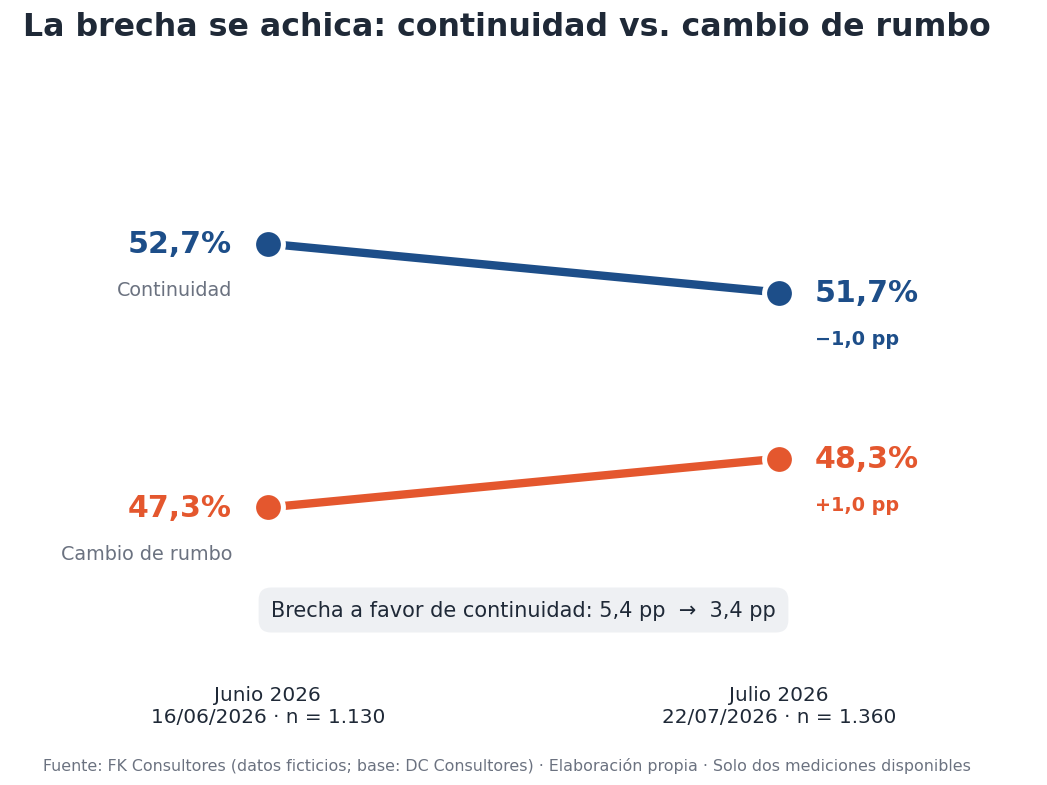

In [39]:
# ============================================================
# EXTRA 6.1 · Evolución Continuidad vs. Cambio de Rumbo
# ============================================================
f0, f1 = enc.iloc[0], enc.iloc[1]
fig, ax = plt.subplots(figsize=(11, 6.6), facecolor=FONDO)

for col, color, nombre in [(COL_CONT, COLOR_CONT, 'Continuidad'),
                           (COL_CAMBIO, COLOR_CAMBIO, 'Cambio de rumbo')]:
    y0, y1 = f0[col], f1[col]
    ax.plot([0, 1], [y0, y1], color=color, lw=5, solid_capstyle='round', zorder=2)
    ax.scatter([0, 1], [y0, y1], s=320, color=color, edgecolor='white', linewidth=3, zorder=3)
    ax.text(-0.07, y0, f'{fmt(y0)}%', ha='right', va='center', fontsize=18, fontweight='bold', color=color)
    ax.text(-0.07, y0 - 0.95, nombre, ha='right', va='center', fontsize=11.5, color=GRIS)
    ax.text(1.07, y1, f'{fmt(y1)}%', ha='left', va='center', fontsize=18, fontweight='bold', color=color)
    ax.text(1.07, y1 - 0.95, f'{fmt_s(y1 - y0)} pp', ha='left', va='center', fontsize=11.5,
            color=color, fontweight='bold')

b0, b1 = abs(f0[COL_CONT] - f0[COL_CAMBIO]), abs(f1[COL_CONT] - f1[COL_CAMBIO])
lider = 'continuidad' if f1[COL_CONT] > f1[COL_CAMBIO] else 'cambio de rumbo'
ax.text(0.5, 45.2, f'Brecha a favor de {lider}: {fmt(b0)} pp  →  {fmt(b1)} pp',
        ha='center', va='center', fontsize=12.5, color=TEXTO,
        bbox=dict(boxstyle='round,pad=0.6', fc=PISTA, ec='none'))

ax.set_xticks([0, 1])
ax.set_xticklabels([f"{titulo_panel(f)}\n{f['Fecha']:%d/%m/%Y} · n = {fmt_n(f['Tamaño de la muestra'])}" for f in (f0, f1)],
                   fontsize=12, color=TEXTO)
ax.tick_params(axis='x', length=0, pad=10)
ax.set_yticks([])
ax.set_xlim(-0.5, 1.5)
ax.set_ylim(44, 56)
ax.grid(False)
for sp in ax.spines.values():
    sp.set_visible(False)
fig.suptitle('La brecha se achica: continuidad vs. cambio de rumbo' if b1 < b0
             else 'Continuidad vs. cambio de rumbo: evolución entre relevamientos',
             fontsize=19, fontweight='bold', color=TEXTO, y=0.97)
pie_figura(fig, f'Fuente: {FUENTE} · Elaboración propia · Solo dos mediciones disponibles')
fig.subplots_adjust(top=0.88, bottom=0.14)
plt.show()

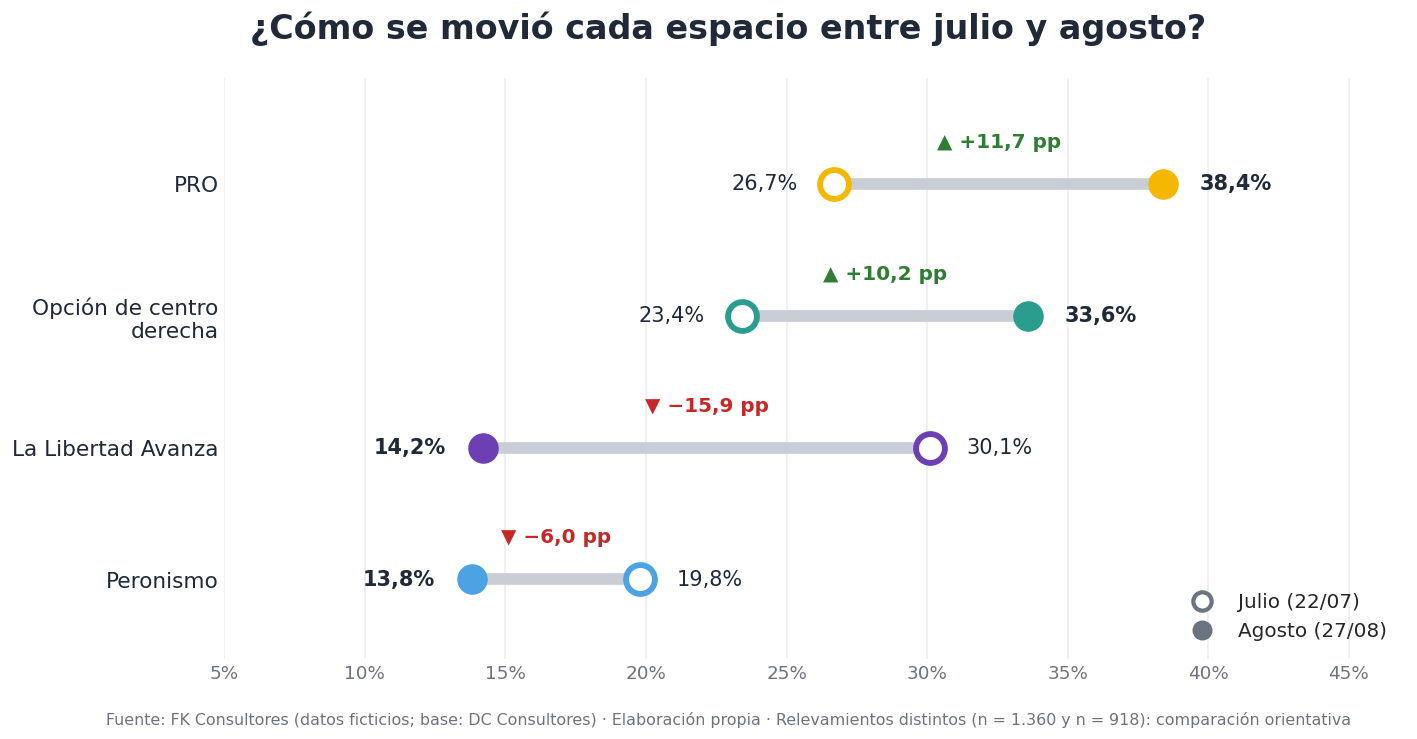

In [40]:
# ============================================================
# EXTRA 6.2 · Cambio por espacio político: julio → agosto (mancuernas)
# ============================================================
v0, v1 = vot.iloc[0], vot.iloc[1]
orden = list(v1[PARTIDOS].astype(float).sort_values().index)       # ordenado por agosto

fig, ax = plt.subplots(figsize=(12, 6.2), facecolor=FONDO)
for i, p in enumerate(orden):
    a, b = float(v0[p]), float(v1[p])
    ax.plot([a, b], [i, i], color='#C9CED6', lw=7, solid_capstyle='round', zorder=1)
    ax.scatter(a, i, s=300, facecolor='white', edgecolor=COLOR_PARTIDO[p], linewidth=3.5, zorder=3)
    ax.scatter(b, i, s=300, color=COLOR_PARTIDO[p], zorder=4)
    for valor, es_agosto in [(a, False), (b, True)]:
        izq = valor == min(a, b)
        ax.text(valor + (-1.3 if izq else 1.3), i, f'{fmt(valor)}%', ha='right' if izq else 'left',
                va='center', fontsize=12.5, color=TEXTO, fontweight='bold' if es_agosto else 'normal')
    flecha = '▲' if b > a else '▼'
    ax.text((a + b) / 2, i + 0.32, f'{flecha} {fmt_s(b - a)} pp', ha='center', va='center',
            fontsize=12, fontweight='bold', color='#2E7D32' if b > a else '#C62828')

ax.set_yticks(range(len(orden)))
ax.set_yticklabels([textwrap.fill(p, 18) for p in orden], fontsize=13, color=TEXTO)
ax.tick_params(axis='y', length=0)
ax.set_xlim(5, 47)
ax.set_ylim(-0.6, len(orden) - 0.2)
ax.xaxis.set_major_formatter(lambda x, _: f'{x:.0f}%')
ax.tick_params(axis='x', labelsize=11, colors=GRIS, length=0)
ax.yaxis.grid(False)
ax.xaxis.grid(True, color=PISTA, lw=1.2)
ax.set_axisbelow(True)
for sp in ax.spines.values():
    sp.set_visible(False)

ax.legend(handles=[Line2D([0], [0], marker='o', ls='', mfc='white', mec=GRIS, mew=2.5, ms=11,
                          label=f"{v0['Mes']} ({v0['Fecha']:%d/%m})"),
                   Line2D([0], [0], marker='o', ls='', color=GRIS, ms=11,
                          label=f"{v1['Mes']} ({v1['Fecha']:%d/%m})")],
          loc='lower right', frameon=False, fontsize=12)
fig.suptitle('¿Cómo se movió cada espacio entre julio y agosto?',
             fontsize=20, fontweight='bold', color=TEXTO, y=0.97)
pie_figura(fig, f"Fuente: {FUENTE} · Elaboración propia · Relevamientos distintos (n = {fmt_n(v0['Tamaño de la muestra'])} y n = {fmt_n(v1['Tamaño de la muestra'])}): comparación orientativa")
fig.subplots_adjust(top=0.88, bottom=0.10, left=0.15, right=0.97)
plt.show()

In [41]:
# ============================================================
# Lectura rápida (se calcula sola con los datos)
# ============================================================
print('📌 LECTURA RÁPIDA\n')
for _, f in enc.iterrows():
    lider = 'Continuidad' if f[COL_CONT] > f[COL_CAMBIO] else 'Cambio de rumbo'
    print(f"• {titulo_panel(f)}: {lider} lidera por {fmt(abs(f[COL_CONT] - f[COL_CAMBIO]))} pp "
          f"({fmt(f[COL_CONT])}% vs. {fmt(f[COL_CAMBIO])}%)")
for _, f in vot.iterrows():
    s = f[PARTIDOS].astype(float).sort_values(ascending=False)
    print(f"• {titulo_panel(f)} (espacios): lidera {s.index[0]} con {fmt(s.iloc[0])}%, seguido de {s.index[1]} ({fmt(s.iloc[1])}%)")
c = vot.iloc[1][CANDIDATOS].astype(float).sort_values(ascending=False)
print(f"• {titulo_panel(vot.iloc[1])} (candidatos, datos ficticios): " + ' · '.join(f'{k} {fmt(v)}%' for k, v in c.items()))

📌 LECTURA RÁPIDA

• Junio 2026: Continuidad lidera por 5,4 pp (52,7% vs. 47,3%)
• Julio 2026: Continuidad lidera por 3,4 pp (51,7% vs. 48,3%)
• Julio 2026 (espacios): lidera La Libertad Avanza con 30,1%, seguido de PRO (26,7%)
• Agosto 2026 (espacios): lidera PRO con 38,4%, seguido de Opción de centro derecha (33,6%)
• Agosto 2026 (candidatos, datos ficticios): Patricia Bullrich 30,4% · Jorge Macri 28,9% · Leandro Santoro 18,3% · Victoria Villarruel 15,2% · Beltrán Briones 7,2%


---
## 7. Resultados electorales en CABA 2025
Se suman dos elecciones para contrastar las encuestas de 2026 con el comportamiento electoral efectivo del distrito:

- **7.1** Elecciones legislativas de la Ciudad (**18 de mayo de 2025**): 30 de las 60 bancas de la Legislatura porteña.
- **7.2** Elecciones nacionales (**26 de octubre de 2025**): 13 diputados nacionales por CABA.
- **7.3** Comparación entre ambas elecciones y **7.4** mapa de ganadores por comuna.

> **Nota sobre la fecha:** la elección de diputados nacionales por CABA se realizó el **26 de octubre de 2025** (en 2026 no hubo elecciones nacionales; las próximas son en 2027), por lo que la notebook usa esa fecha.

**Sobre los datos.** Se cargan a mano en la celda siguiente, a partir de los resultados publicados por el Instituto de Gestión Electoral (IGE) y la Justicia Electoral, y reproducidos por La Nación, Infobae, Chequeado y Palabras del Derecho. Los votos y bancas de octubre corresponden al escrutinio definitivo; los porcentajes de octubre, al escrutinio provisorio, por lo que pueden diferir en décimas de los definitivos. Para mayo, otras fuentes (por ejemplo, Wikipedia) informan porcentajes algo distintos porque usan otro denominador.

In [42]:
# ============================================================
# 7.0 · DATOS ELECTORALES (carga manual desde fuentes publicadas)
# ============================================================
# --- Legislatura porteña · 18/05/2025 (30 bancas en juego) ---
mayo = pd.DataFrame([
    ('La Libertad Avanza',    'Manuel Adorni',       495069, 30.13, 11),
    ('Es Ahora Buenos Aires', 'Leandro Santoro',     449444, 27.35, 10),
    ('Buenos Aires Primero',  'Silvia Lospennato',   261595, 15.92,  5),
    ('Volvamos Buenos Aires', 'Horacio R. Larreta',  132788,  8.08,  3),
    ('FIT-U',                 'Vanina Biasi',         51925,  3.16,  1),
], columns=['Lista', 'Candidato', 'Votos', 'Pct', 'Bancas'])

# --- Diputados nacionales por CABA · 26/10/2025 (13 bancas en juego) ---
# Votos y bancas: escrutinio definitivo. Porcentajes: escrutinio provisorio.
octubre = pd.DataFrame([
    ('Alianza La Libertad Avanza', 'Alejandro Fargosi',    783585, 47.35, 7),
    ('Fuerza Patria',              'Itai Hagman',          445340, 26.97, 4),
    ('FIT-U',                      'Myriam Bregman',       150523,  9.11, 1),
    ('Ciudadanos Unidos',          'Martín Lousteau',       99034,  6.00, 1),
    ('Potencia',                   'Ricardo López Murphy',    np.nan,  4.05, 0),
    ('Hagamos Futuro',             '—',                       np.nan,  1.83, 0),
], columns=['Lista', 'Candidato', 'Votos', 'Pct', 'Bancas'])

# --- Participación y contexto ---
PART_MAYO, PART_OCT = 53.25, 69.30       # % del padrón (octubre: escrutinio provisorio, ~95% de mesas)
PADRON_MAYO, VOTANTES_MAYO = 3_088_750, 1_645_043
resto_mayo = 100 - mayo['Pct'].sum()      # otras listas y votos no atribuidos (residuo)
resto_oct  = 100 - octubre['Pct'].sum()

# --- Ganador por comuna (1 a 15) ---
GANA_MAYO = {c: 'La Libertad Avanza' for c in [1, 2, 6, 7, 10, 11, 12, 13, 14]}
GANA_MAYO.update({c: 'Es Ahora Buenos Aires' for c in [3, 4, 5, 8, 9, 15]})
GANA_OCT = {c: 'Alianza La Libertad Avanza' for c in range(1, 16)}

# --- Colores por lista ---
COLOR_LISTA = {
    'La Libertad Avanza': '#6C3FB5', 'Alianza La Libertad Avanza': '#6C3FB5',
    'Es Ahora Buenos Aires': '#4BA3E3', 'Fuerza Patria': '#4BA3E3',
    'Buenos Aires Primero': '#F5B700', 'Volvamos Buenos Aires': '#2A9D8F',
    'FIT-U': '#D1593F', 'Ciudadanos Unidos': '#7FB069',
    'Potencia': '#8D6E63', 'Hagamos Futuro': '#9AA3B2',
}

def tabla_resultados(df):
    t = df.copy()
    t['Votos'] = t['Votos'].map(lambda v: '—' if pd.isna(v) else fmt_n(v))
    t['Pct'] = t['Pct'].map(lambda v: fmt(v, 2) + '%')
    return t.rename(columns={'Pct': '% votos'})

print(f'✅ Datos electorales cargados · Mayo: {len(mayo)} listas · Octubre: {len(octubre)} listas')
print(f'   Resto de listas (residuo): mayo {fmt(resto_mayo, 2)}% · octubre {fmt(resto_oct, 2)}%')
tabla_resultados(mayo)

✅ Datos electorales cargados · Mayo: 5 listas · Octubre: 6 listas
   Resto de listas (residuo): mayo 15,36% · octubre 4,69%


,Lista,Candidato,Votos,% votos,Bancas
0,La Libertad Avanza,Manuel Adorni,495.069,"30,13%",11
1,Es Ahora Buenos Aires,Leandro Santoro,449.444,"27,35%",10
2,Buenos Aires Primero,Silvia Lospennato,261.595,"15,92%",5
3,Volvamos Buenos Aires,Horacio R. Larreta,132.788,"8,08%",3
4,FIT-U,Vanina Biasi,51.925,"3,16%",1


### 7.1 Legislatura porteña · 18 de mayo de 2025
Resultados por lista (votos, porcentaje y bancas) y participación.

In [43]:
# ============================================================
# Función reutilizable: gráfico de bancas (donut)
# ============================================================
def donut_bancas(ax, df, titulo, subtitulo):
    d = df[df['Bancas'] > 0].sort_values('Bancas', ascending=False)
    total = int(d['Bancas'].sum())
    wedges, _ = ax.pie(d['Bancas'], colors=[COLOR_LISTA[l] for l in d['Lista']], startangle=90,
                       counterclock=False, wedgeprops=dict(width=0.44, edgecolor=FONDO, linewidth=4))
    for w, v in zip(wedges, d['Bancas']):
        ang = np.deg2rad((w.theta1 + w.theta2) / 2)
        ax.text(0.78 * np.cos(ang), 0.78 * np.sin(ang), f'{int(v)}', ha='center', va='center',
                fontsize=16, fontweight='bold', color='white')
    ax.text(0, 0.07, f'{total}', ha='center', va='center', fontsize=30, fontweight='bold', color=TEXTO)
    ax.text(0, -0.2, 'bancas en juego', ha='center', va='center', fontsize=11, color=GRIS)
    ax.set_title(titulo, fontsize=18, fontweight='bold', color=TEXTO, pad=10)
    ax.text(0, -1.3, subtitulo, ha='center', va='center', fontsize=10, color=GRIS)

print('✅ Función donut_bancas definida')

✅ Función donut_bancas definida


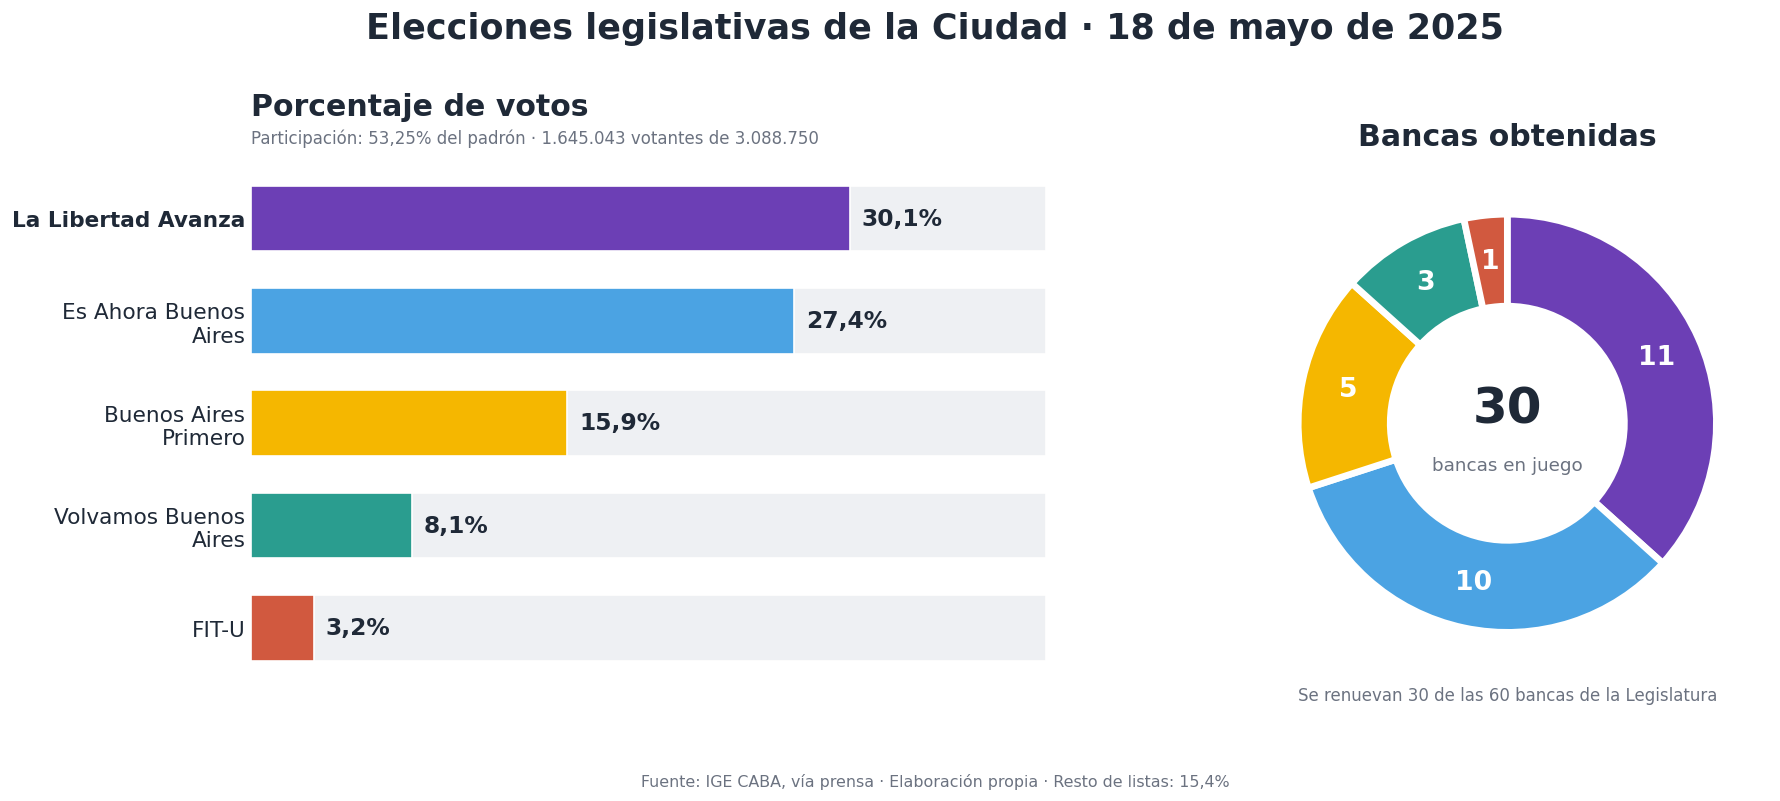

In [44]:
# ============================================================
# GRÁFICO 7.1 · Legislatura porteña · 18 de mayo de 2025
# ============================================================
serie = mayo.set_index('Lista')['Pct'].astype(float)
xmax = np.ceil(serie.max() / 5) * 5 + 5

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6.6), facecolor=FONDO,
                               gridspec_kw={'width_ratios': [1.45, 1]})
barras_h(ax1, serie, COLOR_LISTA, xmax, 'Porcentaje de votos',
         f'Participación: {fmt(PART_MAYO, 2)}% del padrón · {fmt_n(VOTANTES_MAYO)} votantes de {fmt_n(PADRON_MAYO)}')
donut_bancas(ax2, mayo, 'Bancas obtenidas', 'Se renuevan 30 de las 60 bancas de la Legislatura')

fig.suptitle('Elecciones legislativas de la Ciudad · 18 de mayo de 2025',
             fontsize=21, fontweight='bold', color=TEXTO, y=0.99)
pie_figura(fig, f'Fuente: IGE CABA, vía prensa · Elaboración propia · Resto de listas: {fmt(resto_mayo)}%')
fig.subplots_adjust(top=0.80, bottom=0.14, wspace=0.28, left=0.12, right=0.97)
plt.show()

### 7.2 Diputados nacionales por CABA · 26 de octubre de 2025
Resultados por lista. Primero la tabla de resultados y luego el gráfico.

In [45]:
tabla_resultados(octubre)

,Lista,Candidato,Votos,% votos,Bancas
0,Alianza La Libertad Avanza,Alejandro Fargosi,783.585,"47,35%",7
1,Fuerza Patria,Itai Hagman,445.340,"26,97%",4
2,FIT-U,Myriam Bregman,150.523,"9,11%",1
3,Ciudadanos Unidos,Martín Lousteau,99.034,"6,00%",1
4,Potencia,Ricardo López Murphy,—,"4,05%",0
5,Hagamos Futuro,—,—,"1,83%",0


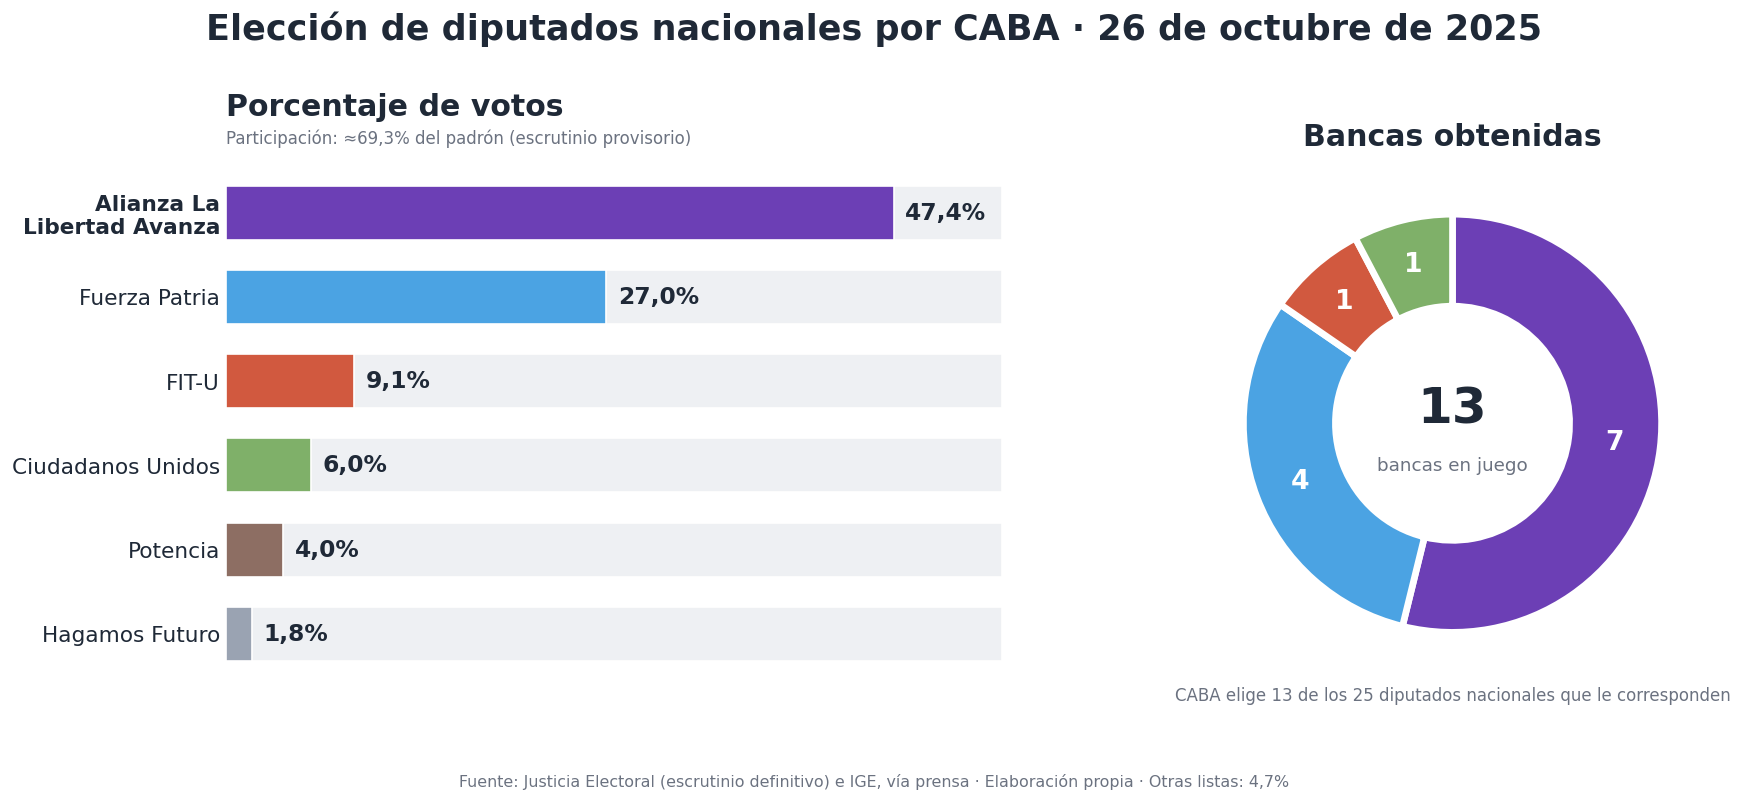

In [46]:
# ============================================================
# GRÁFICO 7.2 · Diputados nacionales por CABA · 26 de octubre de 2025
# ============================================================
serie = octubre.set_index('Lista')['Pct'].astype(float)
xmax = np.ceil(serie.max() / 5) * 5 + 5

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6.6), facecolor=FONDO,
                               gridspec_kw={'width_ratios': [1.45, 1]})
barras_h(ax1, serie, COLOR_LISTA, xmax, 'Porcentaje de votos',
         f'Participación: ≈{fmt(PART_OCT, 1)}% del padrón (escrutinio provisorio)')
donut_bancas(ax2, octubre, 'Bancas obtenidas', 'CABA elige 13 de los 25 diputados nacionales que le corresponden')

fig.suptitle('Elección de diputados nacionales por CABA · 26 de octubre de 2025',
             fontsize=21, fontweight='bold', color=TEXTO, y=0.99)
pie_figura(fig, f'Fuente: Justicia Electoral (escrutinio definitivo) e IGE, vía prensa · Elaboración propia · Otras listas: {fmt(resto_oct)}%')
fig.subplots_adjust(top=0.80, bottom=0.14, wspace=0.28, left=0.14, right=0.97)
plt.show()

### 7.3 Comparación entre ambas elecciones
Se comparan los espacios que pueden equipararse. **Cautela:** en mayo LLA y PRO compitieron por separado y en octubre en alianza; por eso se muestra también su suma. Los espacios de Larreta (Volvamos Buenos Aires) y de Lousteau (Ciudadanos Unidos) no son equivalentes y no se comparan.

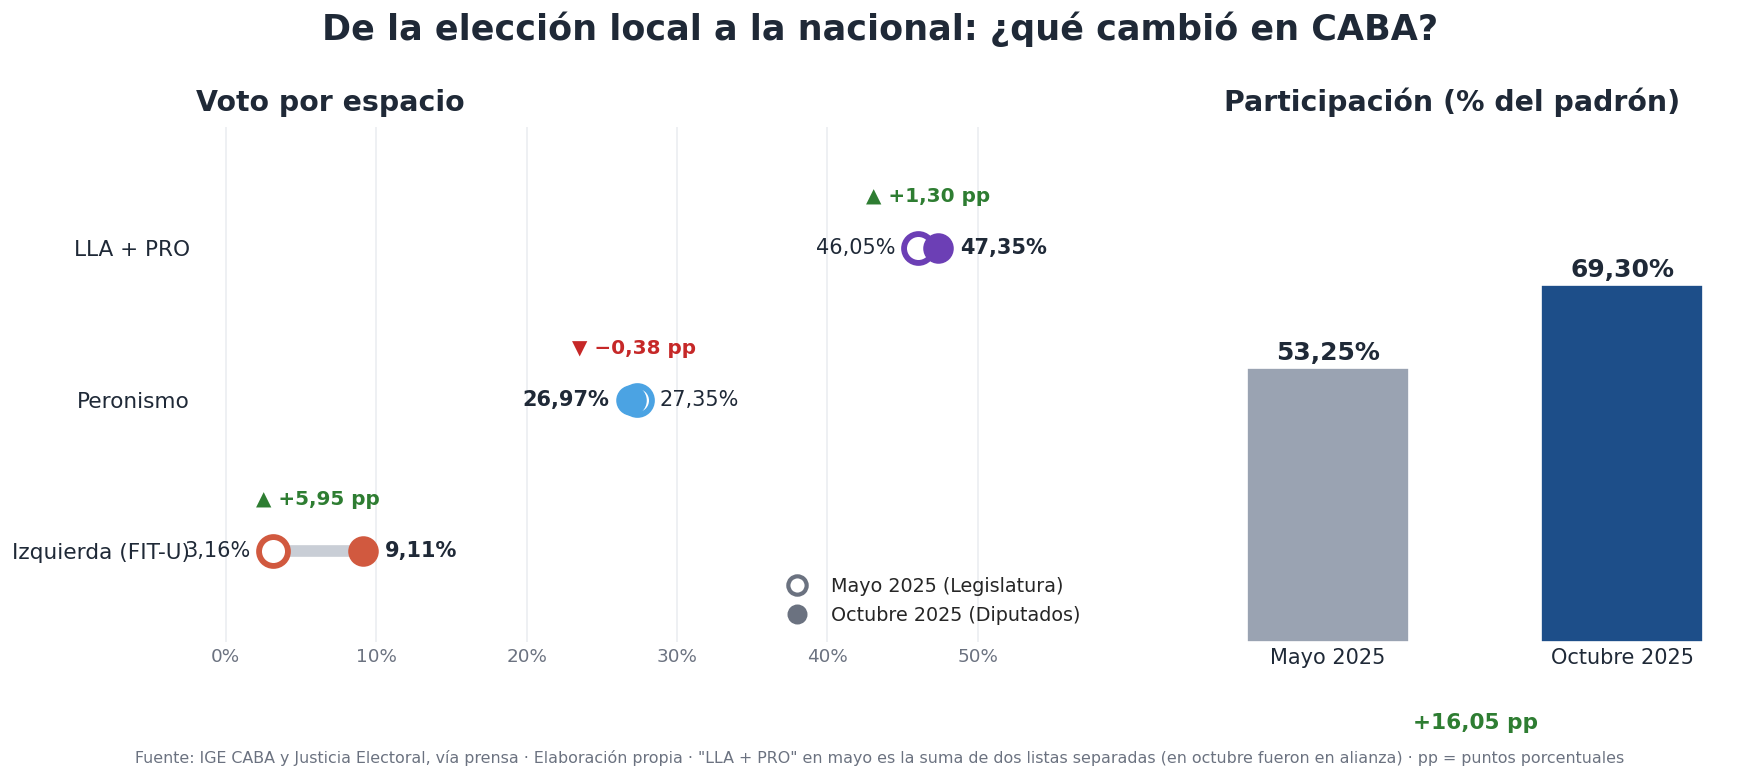

In [47]:
# ============================================================
# GRÁFICO 7.3 · De mayo a octubre: espacios comparables y participación
# ============================================================
lla_pro_mayo = mayo.set_index('Lista').loc[['La Libertad Avanza', 'Buenos Aires Primero'], 'Pct'].sum()
comp = [
    ('LLA + PRO',            lla_pro_mayo,                                          octubre.set_index('Lista').loc['Alianza La Libertad Avanza', 'Pct'], '#6C3FB5'),
    ('Peronismo',            mayo.set_index('Lista').loc['Es Ahora Buenos Aires', 'Pct'], octubre.set_index('Lista').loc['Fuerza Patria', 'Pct'],              '#4BA3E3'),
    ('Izquierda (FIT-U)',    mayo.set_index('Lista').loc['FIT-U', 'Pct'],                 octubre.set_index('Lista').loc['FIT-U', 'Pct'],                      '#D1593F'),
]
comp = sorted(comp, key=lambda r: r[2])   # ordenado por octubre

fig, (ax, axp) = plt.subplots(1, 2, figsize=(15, 6.4), facecolor=FONDO, gridspec_kw={'width_ratios': [1.8, 1]})
for i, (nombre, a, b, color) in enumerate(comp):
    ax.plot([a, b], [i, i], color='#C9CED6', lw=7, solid_capstyle='round', zorder=1)
    ax.scatter(a, i, s=300, facecolor='white', edgecolor=color, linewidth=3.5, zorder=3)
    ax.scatter(b, i, s=300, color=color, zorder=4)
    for valor, es_oct in [(a, False), (b, True)]:
        izq = valor == min(a, b)
        ax.text(valor + (-1.5 if izq else 1.5), i, f'{fmt(valor, 2)}%', ha='right' if izq else 'left',
                va='center', fontsize=12.5, color=TEXTO, fontweight='bold' if es_oct else 'normal')
    ax.text((a + b) / 2, i + 0.34, f"{'▲' if b > a else '▼'} {fmt_s(b - a, 2)} pp", ha='center', va='center',
            fontsize=12, fontweight='bold', color='#2E7D32' if b > a else '#C62828')
ax.set_yticks(range(len(comp)))
ax.set_yticklabels([r[0] for r in comp], fontsize=13, color=TEXTO)
ax.tick_params(axis='y', length=0)
ax.set_xlim(-2, 58)
ax.set_ylim(-0.6, len(comp) - 0.2)
ax.xaxis.set_major_formatter(lambda x, _: f'{x:.0f}%')
ax.tick_params(axis='x', labelsize=11, colors=GRIS, length=0)
ax.yaxis.grid(False); ax.xaxis.grid(True, color=PISTA, lw=1.2); ax.set_axisbelow(True)
for sp in ax.spines.values():
    sp.set_visible(False)
ax.legend(handles=[Line2D([0], [0], marker='o', ls='', mfc='white', mec=GRIS, mew=2.5, ms=11, label='Mayo 2025 (Legislatura)'),
                   Line2D([0], [0], marker='o', ls='', color=GRIS, ms=11, label='Octubre 2025 (Diputados)')],
          loc='lower right', frameon=False, fontsize=11.5)
ax.set_title('Voto por espacio', loc='left', fontsize=17, fontweight='bold', color=TEXTO, pad=10)

# Participación
barras = axp.bar(['Mayo 2025', 'Octubre 2025'], [PART_MAYO, PART_OCT], color=['#9AA3B2', '#1D4E89'], width=0.55, zorder=2)
for b, v in zip(barras, [PART_MAYO, PART_OCT]):
    axp.text(b.get_x() + b.get_width() / 2, v + 1.5, f'{fmt(v, 2)}%', ha='center', fontsize=15, fontweight='bold', color=TEXTO)
axp.set_ylim(0, 100); axp.set_yticks([])
axp.tick_params(axis='x', length=0, labelsize=12.5, labelcolor=TEXTO)
for sp in axp.spines.values():
    sp.set_visible(False)
axp.grid(False)
axp.set_title('Participación (% del padrón)', loc='left', fontsize=17, fontweight='bold', color=TEXTO, pad=10)
axp.text(0.5, -0.17, f'{fmt_s(PART_OCT - PART_MAYO, 2)} pp', transform=axp.transAxes, ha='center', fontsize=13,
         fontweight='bold', color='#2E7D32')

fig.suptitle('De la elección local a la nacional: ¿qué cambió en CABA?', fontsize=21, fontweight='bold', color=TEXTO, y=0.99)
pie_figura(fig, 'Fuente: IGE CABA y Justicia Electoral, vía prensa · Elaboración propia · "LLA + PRO" en mayo es la suma de dos listas separadas (en octubre fueron en alianza) · pp = puntos porcentuales')
fig.subplots_adjust(top=0.84, bottom=0.17, wspace=0.18, left=0.12, right=0.97)
plt.show()

### 7.4 Ganador por comuna
Resumen territorial de ambas elecciones.

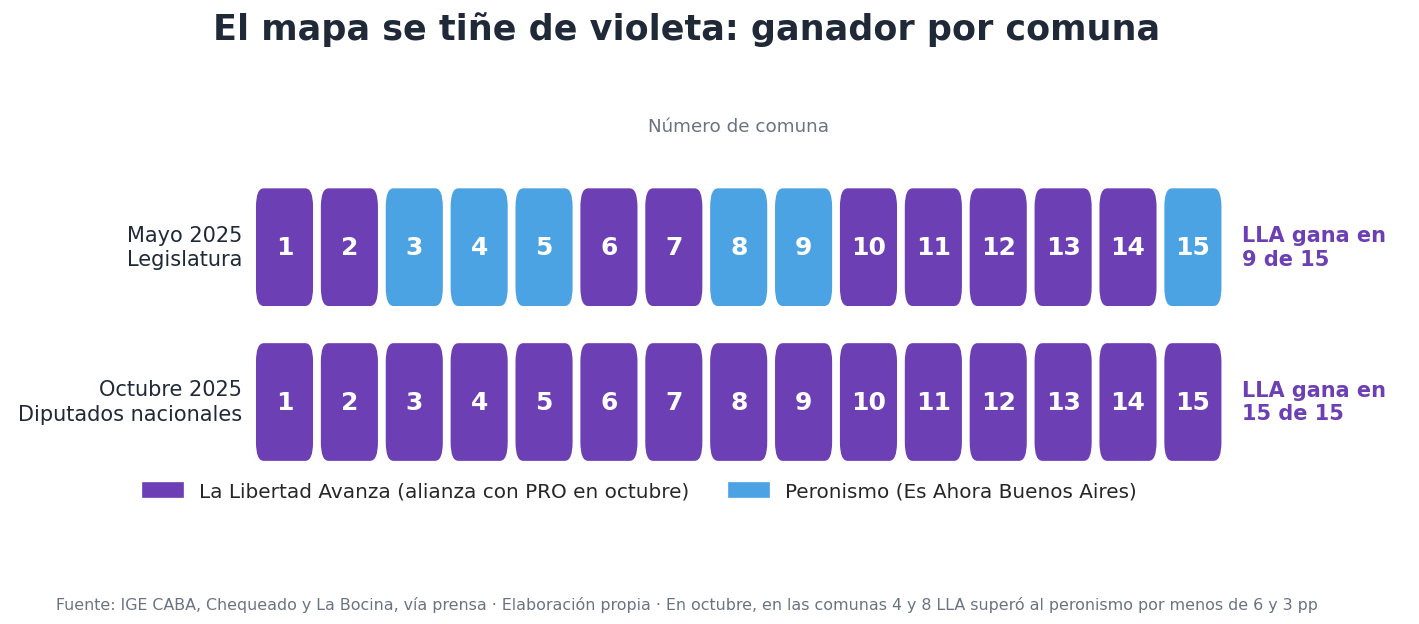

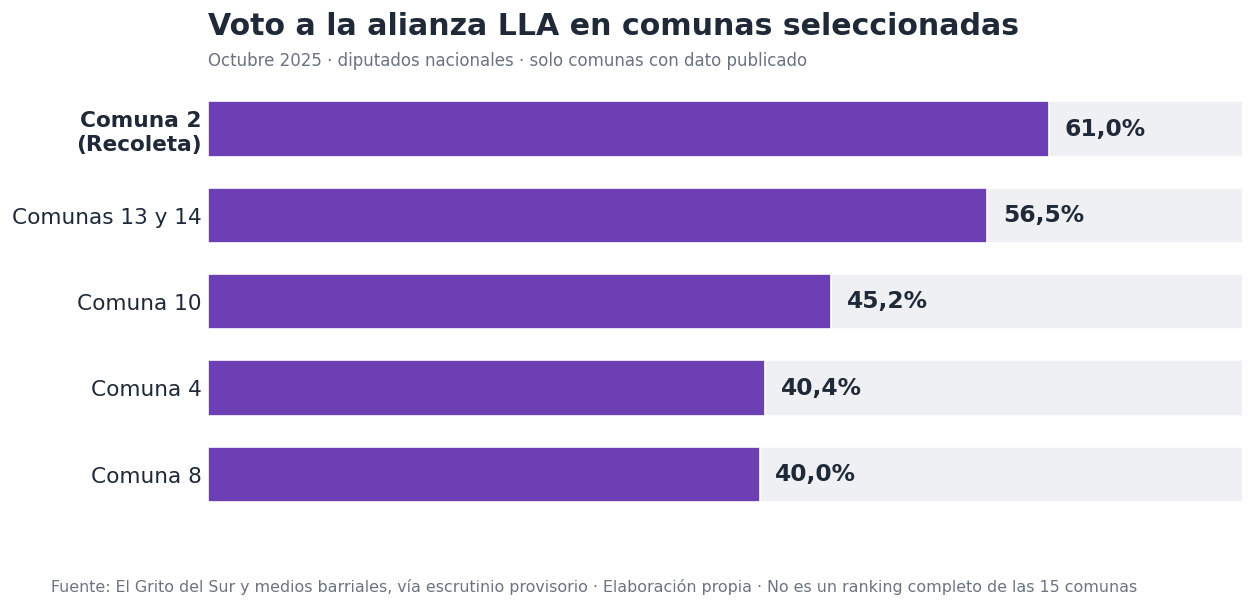

In [48]:
# ============================================================
# GRÁFICO 7.4 · Ganador en cada comuna (mayo vs. octubre de 2025)
# ============================================================
from matplotlib.patches import FancyBboxPatch

fig, ax = plt.subplots(figsize=(15, 5.2), facecolor=FONDO)
filas = [('Mayo 2025\nLegislatura', GANA_MAYO, 1), ('Octubre 2025\nDiputados nacionales', GANA_OCT, 0)]
for etiqueta, ganador, y in filas:
    for c in range(1, 16):
        color = COLOR_LISTA[ganador[c]]
        ax.add_patch(FancyBboxPatch((c - 0.44, y - 0.38), 0.88, 0.76, boxstyle='round,pad=0,rounding_size=0.12',
                                    fc=color, ec='none'))
        ax.text(c, y, str(c), ha='center', va='center', fontsize=15, fontweight='bold', color='white')
    ax.text(0.35, y, etiqueta, ha='right', va='center', fontsize=12.5, color=TEXTO, linespacing=1.3)
    n_lla = sum('Libertad Avanza' in v for v in ganador.values())
    ax.text(15.75, y, f'LLA gana en\n{n_lla} de 15', ha='left', va='center', fontsize=12.5, fontweight='bold', color='#6C3FB5')
ax.text(8, 1.75, 'Número de comuna', ha='center', fontsize=11, color=GRIS)
ax.set_xlim(-3.2, 18.3); ax.set_ylim(-0.7, 2.0); ax.axis('off')
ax.legend(handles=[Patch(color='#6C3FB5', label='La Libertad Avanza (alianza con PRO en octubre)'),
                   Patch(color='#4BA3E3', label='Peronismo (Es Ahora Buenos Aires)')],
          loc='lower center', ncol=2, frameon=False, fontsize=12, bbox_to_anchor=(0.45, -0.02))
fig.suptitle('El mapa se tiñe de violeta: ganador por comuna', fontsize=21, fontweight='bold', color=TEXTO, y=0.97)
pie_figura(fig, 'Fuente: IGE CABA, Chequeado y La Bocina, vía prensa · Elaboración propia · En octubre, en las comunas 4 y 8 LLA superó al peronismo por menos de 6 y 3 pp')
fig.subplots_adjust(top=0.84, bottom=0.17)
plt.show()

# --- Voto a LLA en comunas con dato publicado (octubre, diputados) ---
lla_com = pd.Series({'Comuna 2 (Recoleta)': 60.95, 'Comunas 13 y 14': 56.5, 'Comuna 10': 45.19,
                     'Comuna 4': 40.4, 'Comuna 8': 40.0})
fig, ax = plt.subplots(figsize=(11.5, 5.4), facecolor=FONDO)
barras_h(ax, lla_com, {k: '#6C3FB5' for k in lla_com.index}, 75,
         'Voto a la alianza LLA en comunas seleccionadas',
         'Octubre 2025 · diputados nacionales · solo comunas con dato publicado')
pie_figura(fig, 'Fuente: El Grito del Sur y medios barriales, vía escrutinio provisorio · Elaboración propia · No es un ranking completo de las 15 comunas')
fig.subplots_adjust(top=0.80, bottom=0.12, left=0.22, right=0.97)
plt.show()

In [49]:
# ============================================================
# Lectura rápida de las elecciones (se calcula sola con los datos)
# ============================================================
print('📌 LECTURA RÁPIDA · ELECCIONES 2025\n')
for nombre, df, fecha in [('Legislatura porteña', mayo, '18/05/2025'), ('Diputados nacionales', octubre, '26/10/2025')]:
    d = df.sort_values('Pct', ascending=False)
    print(f"• {nombre} ({fecha}): gana {d.iloc[0]['Lista']} con {fmt(d.iloc[0]['Pct'], 2)}% "
          f"y {int(d.iloc[0]['Bancas'])} bancas; segundo {d.iloc[1]['Lista']} ({fmt(d.iloc[1]['Pct'], 2)}%), "
          f"ventaja de {fmt(d.iloc[0]['Pct'] - d.iloc[1]['Pct'], 2)} pp")
print(f"• Participación: {fmt(PART_MAYO, 2)}% → ≈{fmt(PART_OCT, 1)}% ({fmt_s(PART_OCT - PART_MAYO)} pp)")
print(f"• LLA + PRO (mayo, sumados): {fmt(lla_pro_mayo, 2)}% → alianza en octubre: "
      f"{fmt(octubre.iloc[0]['Pct'], 2)}% ({fmt_s(octubre.iloc[0]['Pct'] - lla_pro_mayo, 2)} pp)")
print(f"• Comunas ganadas por LLA: {sum('Libertad Avanza' in v for v in GANA_MAYO.values())} de 15 en mayo → "
      f"{sum('Libertad Avanza' in v for v in GANA_OCT.values())} de 15 en octubre")

📌 LECTURA RÁPIDA · ELECCIONES 2025

• Legislatura porteña (18/05/2025): gana La Libertad Avanza con 30,13% y 11 bancas; segundo Es Ahora Buenos Aires (27,35%), ventaja de 2,78 pp
• Diputados nacionales (26/10/2025): gana Alianza La Libertad Avanza con 47,35% y 7 bancas; segundo Fuerza Patria (26,97%), ventaja de 20,38 pp
• Participación: 53,25% → ≈69,3% (+16,0 pp)
• LLA + PRO (mayo, sumados): 46,05% → alianza en octubre: 47,35% (+1,30 pp)
• Comunas ganadas por LLA: 9 de 15 en mayo → 15 de 15 en octubre


---
## 8. Clima de opinión nacional y electorado joven (septiembre–octubre 2026)
Se suman tres fuentes de contexto nacional para leer el escenario previo a 2027:

- **8.1** Monitor Socio-Político del Observatorio de Psicología Social Aplicada (**OPSA, UBA**), septiembre de 2026.
- **8.2** Encuesta de Satisfacción Política y Opinión Pública (**ESPOP, Universidad de San Andrés**), octubre de 2026.
- **8.3** Informe *Radiografía del electorado Sub35 rumbo a 2027* (**Eunomia**), octubre de 2026.
- **8.4** Tabla de síntesis.

**Cautelas sobre los datos.** Son relevamientos nacionales, no de CABA, y online (OPSA y ESPOP). Algunas precisiones respecto de la síntesis original:

- El 57% de OPSA corresponde, según la cobertura de prensa, a quienes evalúan mal la *situación política*, no a la desaprobación de la gestión.
- El 39,1% de Eunomia es el peso de las personas de 16 a 35 años sobre la *población de 16 años o más* (proyecciones del INDEC), no sobre el padrón.
- El 19% de Luzu TV proviene del Digital News Report 2026 del Reuters Institute, que Eunomia cita; el promedio general es 13%.
- No pude contrastar con la prensa el 58% de preferencia por un cambio de gobierno, los porcentajes de la agenda de problemas de OPSA (septiembre), los niveles de aprobación por ideología de ESPOP, el 40,2% promedio en el AMBA, ni el 97,8% y 96,5% de uso de celular e internet en jóvenes de 18 a 29 años; se cargan tal como fueron aportados.

In [50]:
# ============================================================
# 8.0 · DATOS DE CLIMA DE OPINIÓN Y ELECTORADO JOVEN
# ============================================================
ficha_nac = pd.DataFrame([
    ('OPSA · Facultad de Psicología, UBA', 'Monitor Socio-Político', 'Sep. 2026', '3.031', 'Online geolocalizada, 18+ (nacional)', '±2,0'),
    ('LOOP · Universidad de San Andrés',   'ESPOP',                  'Oct. 2026', '1.000', 'Online, 18+ (nacional); campo 5–13/10', '±3,15'),
    ('Eunomia (proyecciones INDEC)',       'Radiografía Sub35',      'Oct. 2026', '—',     'Informe demográfico y de consumo', '—'),
], columns=['Institución', 'Estudio', 'Fecha', 'Muestra', 'Metodología', 'Margen de error (pp)'])

# --- OPSA (septiembre 2026) ---
opsa_clima = pd.Series({
    'Situación social: mala o muy mala': 58,
    'Situación política: mala o muy mala': 57,
    'Prefiere un cambio de gobierno en 2027': 58,
})
opsa_agenda = pd.Series({
    'Falta de trabajo / desempleo': 55, 'Bajos salarios': 55,
    'Funcionamiento de la Justicia': 54, 'Corrupción': 54, 'Pobreza': 42,
})
OPSA_SOCIAL_POSITIVA = 19

# --- ESPOP (octubre 2026) ---
espop_marcha = {'Satisfechos': 30, 'Insatisfechos': 67}
espop_gestion = {'Aprueba': 36, 'Desaprueba': 60}
espop_voto = pd.Series({'Peronismo': 24, 'Indecisos / no responde': 26, 'La Libertad Avanza': 26})   # empate en 26%: LLA queda arriba
espop_ideologia = {'Centro-derecha': 56, 'Derecha': 50}      # aprobación del gobierno por ideología

# --- Eunomia (octubre 2026) ---
eun_peso = pd.Series({
    'Nacional (16+ años)': 39.1, 'Prov. de Buenos Aires': 37.8, 'Promedio 40 municipios AMBA': 40.2,
    'Presidente Perón': 46.9, 'Vicente López': 29.5,
})
eun_consumo = pd.Series({
    'Celular (18-29 años)': 97.8, 'Internet (18-29 años)': 96.5,
    'Luzu TV: menores de 35': 19, 'Luzu TV: promedio general': 13,
})

print('✅ Datos de clima de opinión y electorado joven cargados')
ficha_nac

✅ Datos de clima de opinión y electorado joven cargados


,Institución,Estudio,Fecha,Muestra,Metodología,Margen de error (pp)
0,"OPSA · Facultad de Psicología, UBA",Monitor Socio-Político,Sep. 2026,3.031,"Online geolocalizada, 18+ (nacional)","±2,0"
1,LOOP · Universidad de San Andrés,ESPOP,Oct. 2026,1.000,"Online, 18+ (nacional); campo 5–13/10","±3,15"
2,Eunomia (proyecciones INDEC),Radiografía Sub35,Oct. 2026,—,Informe demográfico y de consumo,—


### 8.1 Clima social y agenda de problemas (OPSA)

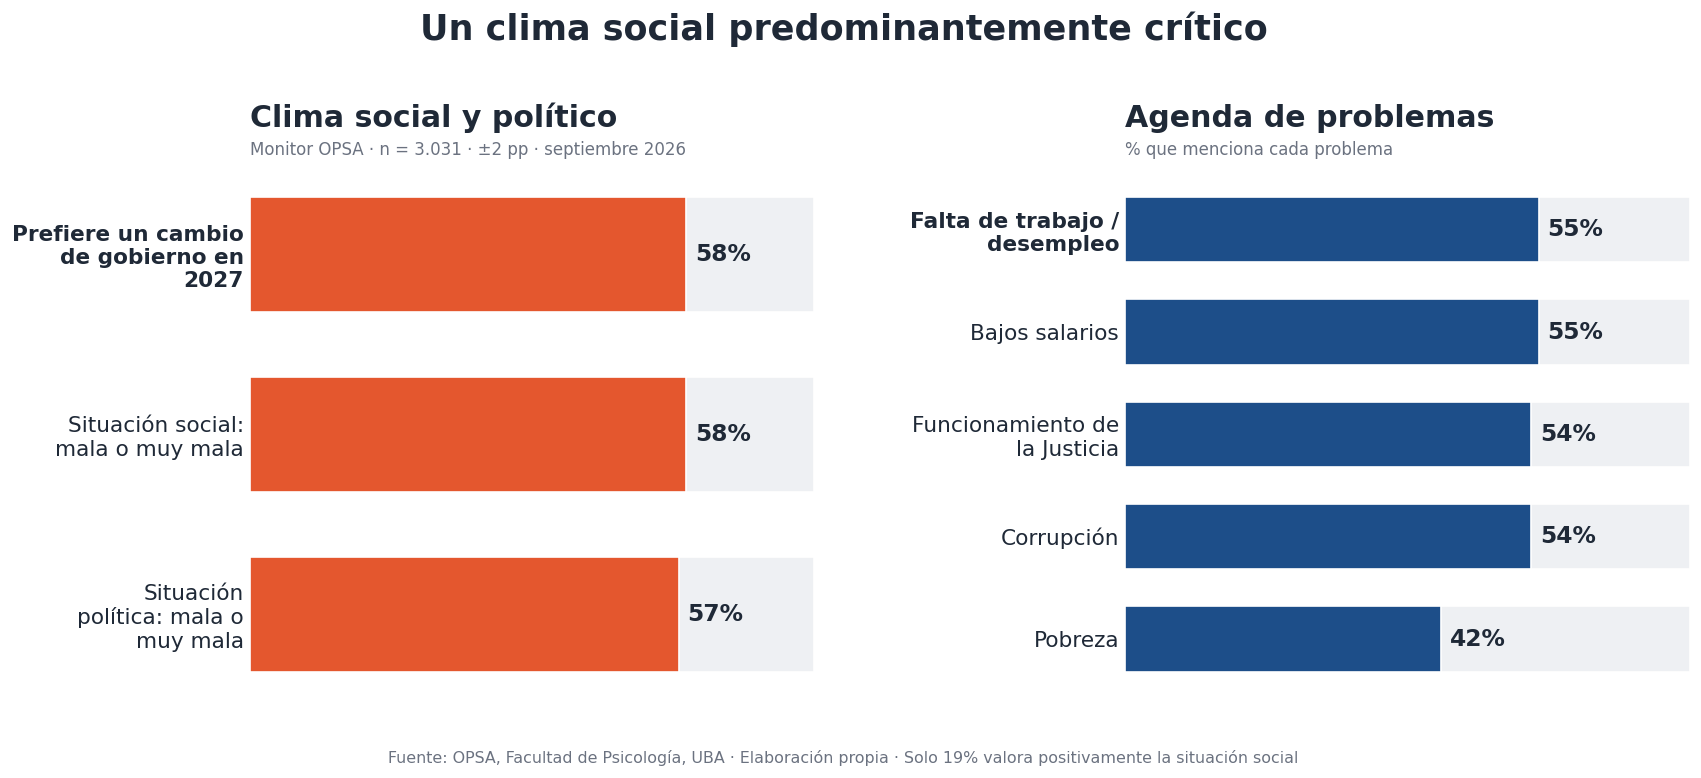

In [51]:
_fmt_orig = fmt
fmt = lambda v, dec=1: _fmt_orig(v, 0 if float(v).is_integer() else dec)   # enteros sin decimales

# ============================================================
# GRÁFICO 8.1 · Clima social (OPSA, septiembre 2026)
# ============================================================
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6.4), facecolor=FONDO)
barras_h(ax1, opsa_clima.astype(float), {k: COLOR_CAMBIO for k in opsa_clima.index}, 75,
         'Clima social y político', 'Monitor OPSA · n = 3.031 · ±2 pp · septiembre 2026')
barras_h(ax2, opsa_agenda.astype(float), {k: COLOR_CONT for k in opsa_agenda.index}, 75,
         'Agenda de problemas', '% que menciona cada problema')
fig.suptitle('Un clima social predominantemente crítico', fontsize=21, fontweight='bold', color=TEXTO, y=0.99)
pie_figura(fig, f'Fuente: OPSA, Facultad de Psicología, UBA · Elaboración propia · Solo {OPSA_SOCIAL_POSITIVA}% valora positivamente la situación social')
fig.subplots_adjust(top=0.78, bottom=0.10, wspace=0.55, left=0.17, right=0.97)
plt.show()
fmt = _fmt_orig

### 8.2 Satisfacción, aprobación e intención de voto 2027 (ESPOP)

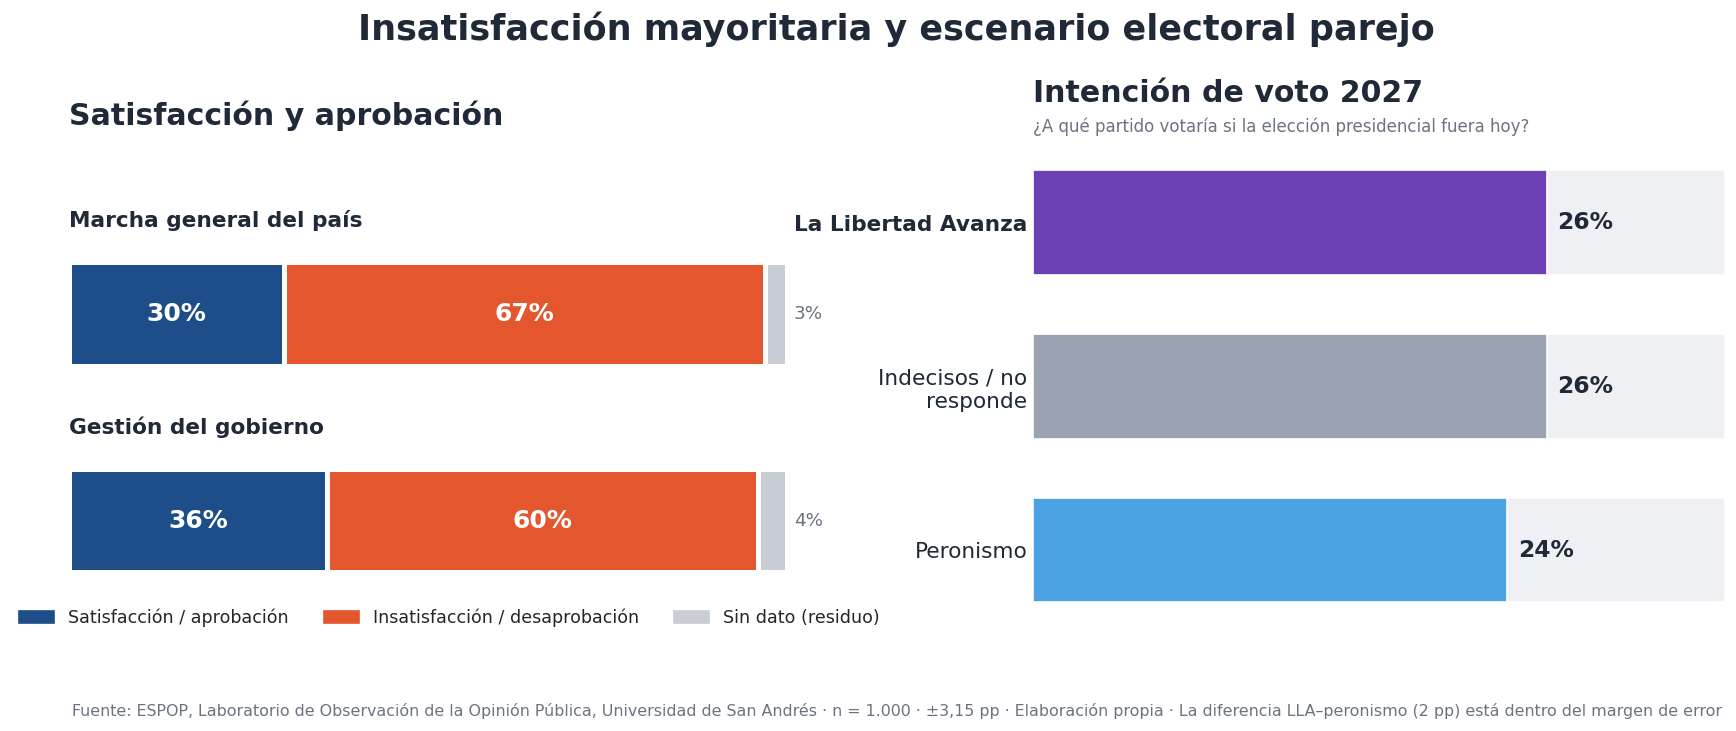

Aprobación del gobierno por ideología (ESPOP): Centro-derecha 56% · Derecha 50%


In [52]:
_fmt_orig = fmt
fmt = lambda v, dec=1: _fmt_orig(v, 0 if float(v).is_integer() else dec)   # enteros sin decimales

# ============================================================
# GRÁFICO 8.2 · ESPOP, Universidad de San Andrés (octubre 2026)
# ============================================================
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6.0), facecolor=FONDO, gridspec_kw={'width_ratios': [1.1, 1]})

# Panel A: barras apiladas satisfacción / aprobación
filas = [('Marcha general del país', espop_marcha, ['Satisfechos', 'Insatisfechos']),
         ('Gestión del gobierno',    espop_gestion, ['Aprueba', 'Desaprueba'])]
for i, (nombre, d, claves) in enumerate(filas[::-1]):
    pos, neg = d[claves[0]], d[claves[1]]
    resto = 100 - pos - neg
    for izq, ancho, color in [(0, pos, COLOR_CONT), (pos, neg, COLOR_CAMBIO), (pos + neg, resto, '#C9CED6')]:
        ax1.barh(i, ancho, left=izq, color=color, height=0.5, edgecolor=FONDO, linewidth=3)
    ax1.text(pos / 2, i, f'{pos}%', ha='center', va='center', color='white', fontsize=15, fontweight='bold')
    ax1.text(pos + neg / 2, i, f'{neg}%', ha='center', va='center', color='white', fontsize=15, fontweight='bold')
    ax1.text(pos + neg + resto + 1, i, f'{resto}%', ha='left', va='center', color=GRIS, fontsize=11)
    ax1.text(0, i + 0.42, nombre, fontsize=13, color=TEXTO, fontweight='bold')
ax1.set_xlim(0, 106); ax1.set_ylim(-0.5, 1.8); ax1.axis('off')
ax1.legend(handles=[Patch(color=COLOR_CONT, label='Satisfacción / aprobación'),
                    Patch(color=COLOR_CAMBIO, label='Insatisfacción / desaprobación'),
                    Patch(color='#C9CED6', label='Sin dato (residuo)')],
           loc='lower center', ncol=3, frameon=False, fontsize=10.5, bbox_to_anchor=(0.5, -0.04))
ax1.set_title('Satisfacción y aprobación', loc='left', fontsize=18, fontweight='bold', color=TEXTO, pad=14)

# Panel B: intención de voto 2027
col_voto = {'La Libertad Avanza': '#6C3FB5', 'Peronismo': '#4BA3E3', 'Indecisos / no responde': '#9AA3B2'}
barras_h(ax2, espop_voto.astype(float), col_voto, 35, 'Intención de voto 2027',
         '¿A qué partido votaría si la elección presidencial fuera hoy?')

fig.suptitle('Insatisfacción mayoritaria y escenario electoral parejo', fontsize=21, fontweight='bold', color=TEXTO, y=0.99)
pie_figura(fig, 'Fuente: ESPOP, Laboratorio de Observación de la Opinión Pública, Universidad de San Andrés · n = 1.000 · ±3,15 pp · Elaboración propia · La diferencia LLA–peronismo (2 pp) está dentro del margen de error')
fig.subplots_adjust(top=0.80, bottom=0.14, wspace=0.28, left=0.04, right=0.96)
plt.show()
fmt = _fmt_orig

print(f"Aprobación del gobierno por ideología (ESPOP): "
      + ' · '.join(f'{k} {v}%' for k, v in espop_ideologia.items()))

### 8.3 Electorado Sub35 y canales de consumo (Eunomia)
El electorado de 16 a 35 años pesará casi cuatro de cada diez personas en edad de votar en 2027, con consumo *mobile-first* y nuevas puertas de entrada informativas (streaming y canales de creadores).

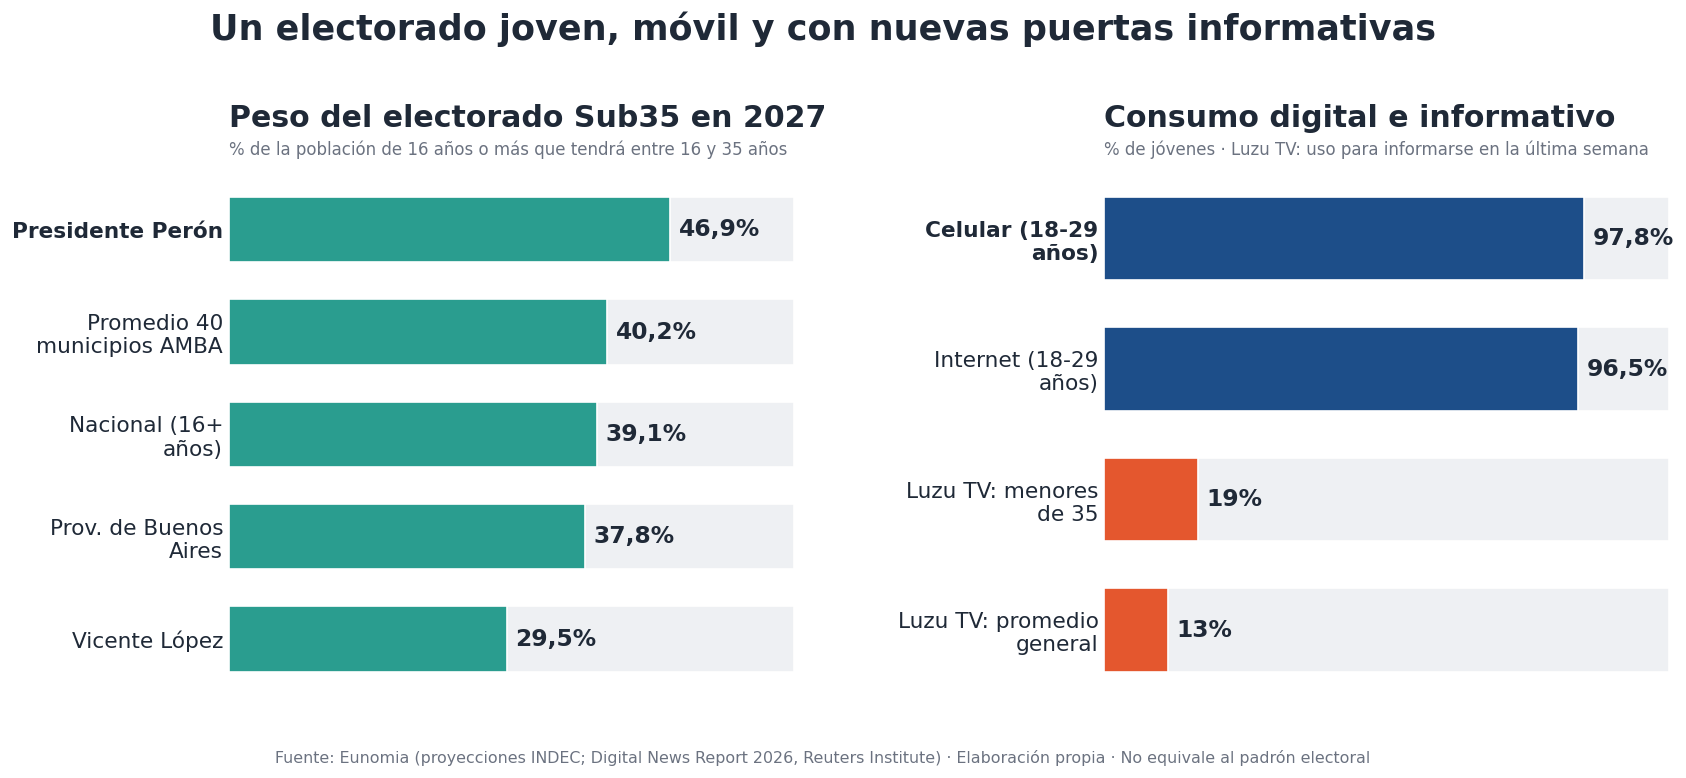

In [53]:
_fmt_orig = fmt
fmt = lambda v, dec=1: _fmt_orig(v, 0 if float(v).is_integer() else dec)   # enteros sin decimales

# ============================================================
# GRÁFICO 8.3 · Electorado Sub35 (Eunomia, octubre 2026)
# ============================================================
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6.4), facecolor=FONDO)
barras_h(ax1, eun_peso.astype(float), {k: '#2A9D8F' for k in eun_peso.index}, 60,
         'Peso del electorado Sub35 en 2027', '% de la población de 16 años o más que tendrá entre 16 y 35 años')
barras_h(ax2, eun_consumo.astype(float), {k: '#E4572E' if 'Luzu' in k else '#1D4E89' for k in eun_consumo.index}, 115,
         'Consumo digital e informativo', '% de jóvenes · Luzu TV: uso para informarse en la última semana')
fig.suptitle('Un electorado joven, móvil y con nuevas puertas informativas', fontsize=21, fontweight='bold', color=TEXTO, y=0.99)
pie_figura(fig, 'Fuente: Eunomia (proyecciones INDEC; Digital News Report 2026, Reuters Institute) · Elaboración propia · No equivale al padrón electoral')
fig.subplots_adjust(top=0.78, bottom=0.10, wspace=0.55, left=0.17, right=0.97)
plt.show()
fmt = _fmt_orig

### 8.4 Tabla de síntesis

In [54]:
# ============================================================
# 8.4 · Tabla 1: síntesis del clima socioeconómico y de opinión pública
# ============================================================
tabla1 = pd.DataFrame([
    ('Clima social (OPSA)',        'Evaluación social',     '58% mala/muy mala | 19% positiva',
     'Demanda de soluciones urgentes y fin de la retórica partidaria.'),
    ('Evaluación de gestión (UDESA)', 'Aprobación presidencial', '60% desaprueba | 36% aprueba',
     'Fuerte polarización y desgaste de liderazgos tradicionales.'),
    ('Demandas clave (OPSA)',      'Agenda de problemas',   'Empleo 55% | Salarios 55% | Pobreza 42%',
     'Prevalencia de variables económicas sobre discursos ideológicos.'),
    ('Escenario electoral (ESPOP)', 'Tendencia 2027',       'LLA 26% | Peronismo 24% | Indecisos 26%',
     'Paridad técnica y centralidad del votante de centro-derecha independiente.'),
], columns=['Dimensión analizada', 'Indicador empírico', 'Distribución de datos', 'Implicación política'])
tabla1

,Dimensión analizada,Indicador empírico,Distribución de datos,Implicación política
0,Clima social (OPSA),Evaluación social,58% mala/muy mala | 19% positiva,Demanda de soluciones urgentes y fin de la ret...
1,Evaluación de gestión (UDESA),Aprobación presidencial,60% desaprueba | 36% aprueba,Fuerte polarización y desgaste de liderazgos t...
2,Demandas clave (OPSA),Agenda de problemas,Empleo 55% | Salarios 55% | Pobreza 42%,Prevalencia de variables económicas sobre disc...
3,Escenario electoral (ESPOP),Tendencia 2027,LLA 26% | Peronismo 24% | Indecisos 26%,Paridad técnica y centralidad del votante de c...


---
## 9. Principales preocupaciones de la ciudadanía de CABA (encuestas reales, 2026)
Se suman tres relevamientos **reales** de 2026 que indagan en las preocupaciones, temores y reclamos de los habitantes de la Ciudad:

- **9.1** DC Consultores, *CABA en refacción* (campo del 23 al 27 de agosto de 2026): temores, reclamos a la gestión y perfil del gobernante ideal.
- **9.2** DC Consultores (campo del 22 al 26 de octubre de 2026, n = 1.360, ±2,5 pp): presión tributaria y percepción de inseguridad nocturna.
- **9.3** OPSA, Facultad de Psicología, UBA (abril de 2026, n = 1.505): preocupaciones personales en el **AMBA** (Ciudad y Gran Buenos Aires).
- **9.4** Tabla de síntesis.

**Cautelas sobre los datos.**

- Estas encuestas de DC Consultores son **reales** y se toman de la cobertura de prensa; no son las de la serie ficticia FK Consultores de las secciones 3 a 6.
- La nota de prensa de la encuesta de agosto no informa la muestra ni el margen de error.
- El estudio de OPSA incluye también el Gran Buenos Aires, por lo que no es exclusivo de CABA.
- Las preguntas, las opciones de respuesta y los métodos son distintos en cada estudio, y las notas no siempre aclaran si se podía elegir más de una opción; por eso los porcentajes no deben sumarse ni compararse de forma directa.
- Sobre los operativos de seguridad en barrios populares, las notas publicadas invierten los porcentajes (41,3% y 39,2%), por lo que ese dato no se incluye. El dato de los lugares donde se evita esperar de noche y el de Ingresos Brutos (19%) provienen de una sola nota cada uno.
- No encontré otros relevamientos de 2026 exclusivos de CABA con un ranking de problemas; los últimos con ese formato son de 2025.

In [55]:
# ============================================================
# 9.0 · DATOS: PREOCUPACIONES DE LA CIUDADANÍA (encuestas reales 2026)
# ============================================================
ficha_preoc = pd.DataFrame([
    ('DC Consultores', 'CABA en refacción', '23–27/08/2026', 'No informada', 'No informado', 'CABA'),
    ('DC Consultores', 'Encuesta CABA',      '22–26/10/2026', '1.360',        '±2,5',         'CABA'),
    ('OPSA · Facultad de Psicología, UBA', 'Clima emocional AMBA', '1–8/04/2026', '1.505', 'No informado', 'CABA y Gran Buenos Aires'),
], columns=['Consultora', 'Estudio', 'Campo', 'Muestra', 'Margen de error (pp)', 'Ámbito'])

# --- DC Consultores · agosto 2026 (% de menciones) ---
dc_temores = pd.Series({
    'Que el peronismo u otro partido gobierne la Ciudad': 33.7,
    'Que nada cambie, todo siga igual': 29.8,
    'Que el PRO pierda su identidad': 19.1,
    'Aumento del ABL e Ingresos Brutos': 17.5,
})
dc_reclamos = pd.Series({
    'Resultados puntuales': 44.6,
    'Una visión de futuro, no solo gestión diaria': 33.1,
    'Cercanía real con los vecinos': 15.9,
    'Nada, vamos bien': 6.4,
})
dc_dirigente = pd.Series({
    'Que resuelva lo cotidiano sin discursos': 53.7,
    'Que no suba impuestos ni tasas': 24.1,
    'Que dialogue, sin imponer un modelo único': 14.8,
    'Que no dependa de decisiones de Nación': 7.4,
})
dc_ciudad = pd.Series({
    'En refacción, con la familia viviendo adentro': 61.9,
    'La misma de siempre, nadie tocó nada': 24.2,
    'Cerrada con llave, esperando a ver quién entra': 7.6,
    'Recién pintada y en orden': 6.3,
})

# --- DC Consultores · octubre 2026 ---
dc_boleta = pd.Series({'ABL': 34.9, 'Multas y fotomultas': 27.6, 'Ingresos Brutos': 19.0})
dc_escepticismo = pd.Series({'Es una movida electoral': 33.6, 'Lo que baja por un lado sube por otro': 22.4})
dc_recorte = pd.Series({'Publicidad oficial': 42.3, 'Direcciones y áreas de estructura política': 31.6})
dc_noche = pd.Series({'Retiro': 34.8, 'Constitución': 33.9})   # lugares donde evitan esperar solos de noche (solo se publicaron estos dos)

# --- OPSA UBA · abril 2026 (AMBA) ---
opsa_personal = pd.Series({
    'Que el país siga en decadencia': 53, 'No llegar a fin de mes': 52,
    'Mi futuro laboral': 46, 'No poder realizar mis proyectos': 44,
})

COLOR_DC, COLOR_DC2, COLOR_OPSA = '#1D4E89', '#2A9D8F', '#E4572E'
def solo(serie, color):
    return {k: color for k in serie.index}

print('✅ Datos de preocupaciones cargados')
ficha_preoc

✅ Datos de preocupaciones cargados


,Consultora,Estudio,Campo,Muestra,Margen de error (pp),Ámbito
0,DC Consultores,CABA en refacción,23–27/08/2026,No informada,No informado,CABA
1,DC Consultores,Encuesta CABA,22–26/10/2026,1.360,"±2,5",CABA
2,"OPSA · Facultad de Psicología, UBA",Clima emocional AMBA,1–8/04/2026,1.505,No informado,CABA y Gran Buenos Aires


### 9.1 Temores y reclamos en CABA (DC Consultores, agosto 2026)

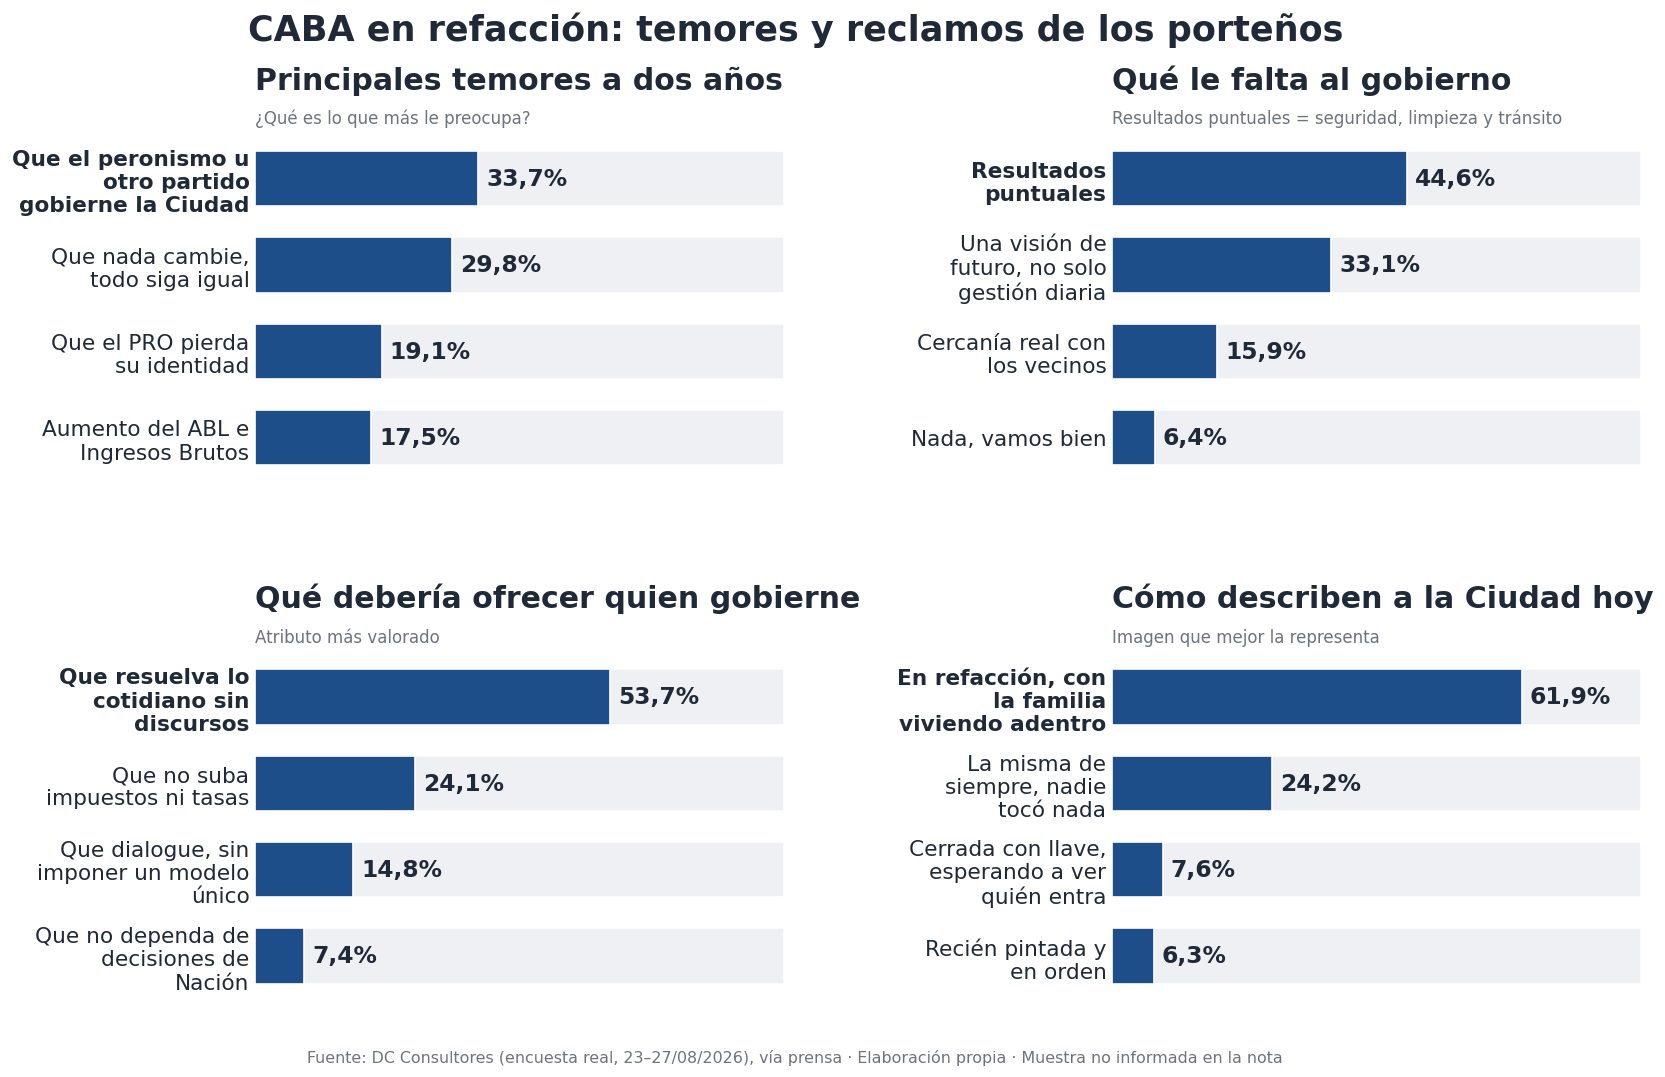

In [56]:
_fmt_orig = fmt
fmt = lambda v, dec=1: _fmt_orig(v, 0 if float(v).is_integer() else dec)   # enteros sin decimales

# ============================================================
# GRÁFICO 9.1 · DC Consultores, "CABA en refacción" (agosto 2026)
# ============================================================
fig, axes = plt.subplots(2, 2, figsize=(15, 9.0), facecolor=FONDO)
paneles = [
    (dc_temores,   'Principales temores a dos años',     '¿Qué es lo que más le preocupa?'),
    (dc_reclamos,  'Qué le falta al gobierno', 'Resultados puntuales = seguridad, limpieza y tránsito'),
    (dc_dirigente, 'Qué debería ofrecer quien gobierne', 'Atributo más valorado'),
    (dc_ciudad,    'Cómo describen a la Ciudad hoy',      'Imagen que mejor la representa'),
]
for ax, (serie, titulo, sub) in zip(axes.ravel(), paneles):
    barras_h(ax, serie.astype(float), solo(serie, COLOR_DC), 80, titulo, sub)
fig.suptitle('CABA en refacción: temores y reclamos de los porteños', fontsize=21, fontweight='bold', color=TEXTO, y=0.985)
pie_figura(fig, 'Fuente: DC Consultores (encuesta real, 23–27/08/2026), vía prensa · Elaboración propia · Muestra no informada en la nota')
fig.subplots_adjust(top=0.87, bottom=0.07, wspace=0.62, hspace=0.5, left=0.2, right=0.97)
plt.show()
fmt = _fmt_orig

### 9.2 Presión tributaria e inseguridad nocturna (DC Consultores, octubre 2026)

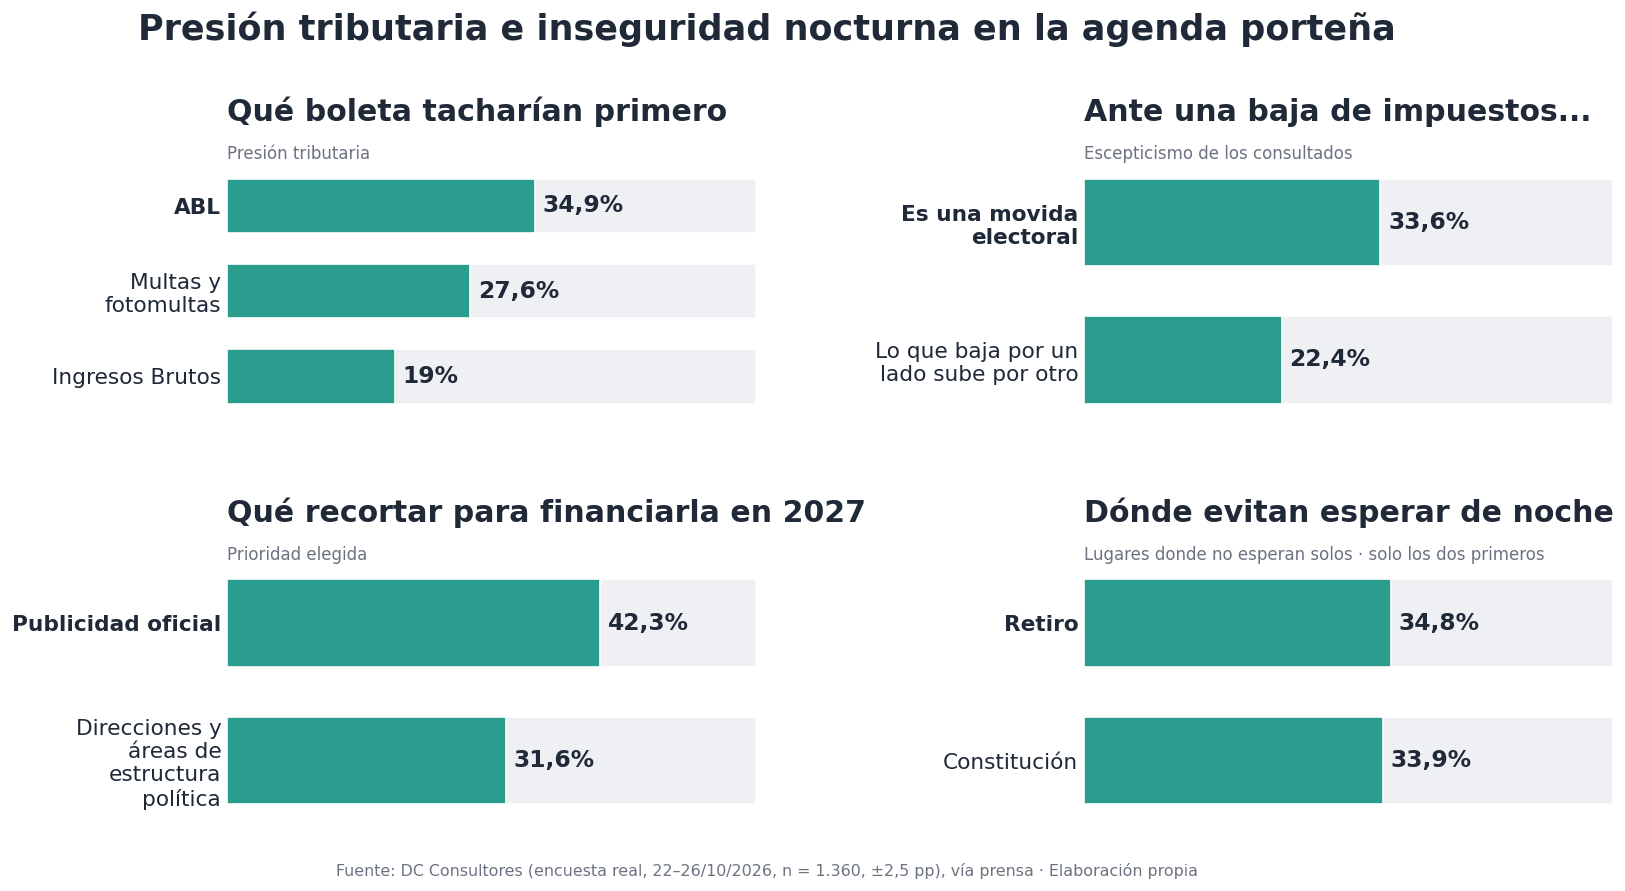

In [57]:
_fmt_orig = fmt
fmt = lambda v, dec=1: _fmt_orig(v, 0 if float(v).is_integer() else dec)

# ============================================================
# GRÁFICO 9.2 · DC Consultores (octubre 2026): presión tributaria e inseguridad nocturna
# ============================================================
fig, axes = plt.subplots(2, 2, figsize=(15, 7.4), facecolor=FONDO)
paneles = [
    (dc_boleta,       'Qué boleta tacharían primero',        'Presión tributaria'),
    (dc_escepticismo, 'Ante una baja de impuestos...',        'Escepticismo de los consultados'),
    (dc_recorte,      'Qué recortar para financiarla en 2027', 'Prioridad elegida'),
    (dc_noche,        'Dónde evitan esperar de noche',        'Lugares donde no esperan solos · solo los dos primeros'),
]
for ax, (serie, titulo, sub) in zip(axes.ravel(), paneles):
    barras_h(ax, serie.astype(float), solo(serie, COLOR_DC2), 60, titulo, sub)
fig.suptitle('Presión tributaria e inseguridad nocturna en la agenda porteña', fontsize=21, fontweight='bold', color=TEXTO, y=0.985)
pie_figura(fig, 'Fuente: DC Consultores (encuesta real, 22–26/10/2026, n = 1.360, ±2,5 pp), vía prensa · Elaboración propia')
fig.subplots_adjust(top=0.81, bottom=0.08, wspace=0.62, hspace=0.62, left=0.2, right=0.97)
plt.show()
fmt = _fmt_orig

### 9.3 Preocupaciones personales en el AMBA (OPSA UBA, abril 2026)

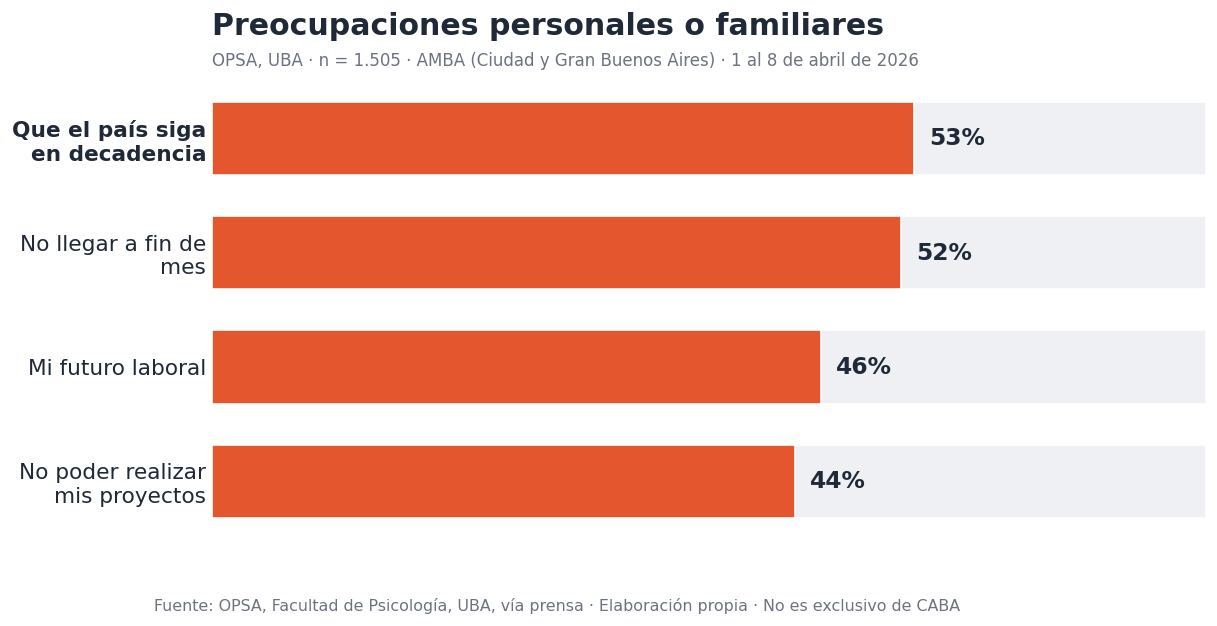

In [58]:
_fmt_orig = fmt
fmt = lambda v, dec=1: _fmt_orig(v, 0 if float(v).is_integer() else dec)

# ============================================================
# GRÁFICO 9.3 · OPSA UBA (abril 2026): preocupaciones personales en el AMBA
# ============================================================
fig, ax = plt.subplots(figsize=(11.5, 5.6), facecolor=FONDO)
barras_h(ax, opsa_personal.astype(float), solo(opsa_personal, COLOR_OPSA), 75,
         'Preocupaciones personales o familiares',
         'OPSA, UBA · n = 1.505 · AMBA (Ciudad y Gran Buenos Aires) · 1 al 8 de abril de 2026')
pie_figura(fig, 'Fuente: OPSA, Facultad de Psicología, UBA, vía prensa · Elaboración propia · No es exclusivo de CABA')
fig.subplots_adjust(top=0.80, bottom=0.12, left=0.25, right=0.97)
plt.show()
fmt = _fmt_orig

### 9.4 Tabla de síntesis

In [59]:
# ============================================================
# 9.4 · Síntesis de las preocupaciones (encuestas reales 2026)
# ============================================================
tabla_preoc = pd.DataFrame([
    ('DC Consultores · ago. 2026', 'CABA', 'Principal temor a dos años', 'Que el peronismo u otro partido gobierne la Ciudad (33,7%)'),
    ('DC Consultores · ago. 2026', 'CABA', 'Principal reclamo a la gestión', 'Resultados puntuales: seguridad, limpieza y tránsito (44,6%)'),
    ('DC Consultores · oct. 2026', 'CABA', 'Principal reclamo tributario', 'El ABL (34,9%) y las multas y fotomultas (27,6%)'),
    ('OPSA UBA · abr. 2026',       'AMBA', 'Preocupación personal o familiar', 'Que el país siga en decadencia (53%) y no llegar a fin de mes (52%)'),
], columns=['Encuesta', 'Ámbito', 'Pregunta', 'Dato principal'])
tabla_preoc

,Encuesta,Ámbito,Pregunta,Dato principal
0,DC Consultores · ago. 2026,CABA,Principal temor a dos años,Que el peronismo u otro partido gobierne la Ci...
1,DC Consultores · ago. 2026,CABA,Principal reclamo a la gestión,"Resultados puntuales: seguridad, limpieza y tr..."
2,DC Consultores · oct. 2026,CABA,Principal reclamo tributario,"El ABL (34,9%) y las multas y fotomultas (27,6%)"
3,OPSA UBA · abr. 2026,AMBA,Preocupación personal o familiar,Que el país siga en decadencia (53%) y no lleg...


In [60]:
# ============================================================
# Lectura rápida de las preocupaciones (se calcula sola con los datos)
# ============================================================
print('📌 LECTURA RÁPIDA · PREOCUPACIONES 2026\n')
for nombre, s in [('DC ago. · temores', dc_temores), ('DC ago. · reclamos', dc_reclamos), ('DC oct. · boleta a tachar', dc_boleta), ('OPSA abr. (AMBA)', opsa_personal)]:
    s = s.sort_values(ascending=False)
    print(f"• {nombre}: {s.index[0]} ({fmt(s.iloc[0])}%), seguido de {s.index[1]} ({fmt(s.iloc[1])}%)")

📌 LECTURA RÁPIDA · PREOCUPACIONES 2026

• DC ago. · temores: Que el peronismo u otro partido gobierne la Ciudad (33,7%), seguido de Que nada cambie, todo siga igual (29,8%)
• DC ago. · reclamos: Resultados puntuales (44,6%), seguido de Una visión de futuro, no solo gestión diaria (33,1%)
• DC oct. · boleta a tachar: ABL (34,9%), seguido de Multas y fotomultas (27,6%)
• OPSA abr. (AMBA): Que el país siga en decadencia (53,0%), seguido de No llegar a fin de mes (52,0%)
